# IMPORTS

In [ ]:
import csv 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from pathlib import Path
import sys
sys.path.append(os.path.join(os.getcwd(), '..'))
from utils.eda_helpers import read_csv_numeric

file_path = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
DATA_FOLDER = os.path.join(file_path, '..', 'dataset')

np.random.seed(42)

In [ ]:
repo_root = os.path.abspath(os.path.join(".."))

save_dir = os.path.join(repo_root, "results", "eda")
os.makedirs(save_dir, exist_ok=True)
print(f"All outputs will be saved under: {save_dir}")

plots_dir = os.path.join(repo_root, "plots", "eda")
os.makedirs(plots_dir, exist_ok=True)
print(f"All plots will be saved under: {plots_dir}")

# define subdirectory for category plots
plots_categories_dir = os.path.join(plots_dir, "categories")
os.makedirs(plots_categories_dir, exist_ok=True)

All outputs will be saved under: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\results\eda
All plots will be saved under: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda


In [ ]:
x_indices, x_data = read_csv_numeric(os.path.join(DATA_FOLDER, "x_train.csv"))
y_indices, y_data = read_csv_numeric(os.path.join(DATA_FOLDER, "y_train.csv"))

# 1. Reduced feature set

In [5]:
# reduced feature set (after removing high na, duplicates, not interesting etc)
reduced_feature_set = ['_CASTHM1', 'FLUSHOT6', 'METVL11_', '_PASTAE1', '_PASTRNG', 'EDUCA', '_RFHLTH', 'CHCCOPD1', 'DRADVISE', 
                        'CHCKIDNY', 'ARTHSOCL', 'SMOKDAY2', '_RFSEAT2', '_MISVEGN', 'WTCHSALT', 'MENTHLTH', 'SMOKE100', 'DOCTDIAB', 
                        'DIABAGE2', 'VETERAN3', 'CHKHEMO3', 'SEX', '_DRNKWEK', 'JOINPAIN', 'MARITAL', 'EXERANY2', '_TOTINDA', '_PACAT1', 
                        'INSULIN', 'DROCDY3_', 'DIFFALON', 'FRUIT1', 'QLACTLM2', 'BLIND', 'MAXDRNKS', '_LMTWRK1', 'RENTHOM1', 'PAMIN11_', 
                        'PADUR2_', 'STOPSMK2', 'PAFREQ2_', 'LMTJOIN3', 'CHOLCHK', 'POORHLTH', 'FRUTDA1_', 'DIABETE3', '_FRUTSUM', '_LMTACT1',
                        'PERSDOC2', 'STRFREQ_', 'EXRACT21', 'FEETCHK', '_VEGESUM', 'PNEUVAC3', 'DRNK3GE5', 'ALCDAY5', 'BPHIGH4', 'GENHLTH',
                        'EXRACT11', '_FRUITEX', '_BMI5', 'PAVIG11_', 'DECIDE', '_ASTHMS1', '_MRACE1', '_LMTSCL1', 'AVEDRNK2', 'ORNGDAY_', 
                        '_MISFRTN', 'MSCODE', 'PHYSHLTH', 'TOLDHI2', '_SMOKER3', 'PADUR1_', 'DIFFWALK', 'BEANDAY_', 'WTKG3', 'CHCSCNCR', 
                        'PAFREQ1_', '_AIDTST3', 'FLSHTMY2', 'PA1VIGM_', 'HIVTST6', 'METVL21_', '_PAINDX1', 'SXORIENT', 'ARTHDIS2', 'PA1MIN_', 
                        'MAXVO2_', 'VEGEDA1_', '_RACE_G1', 'GRENDAY_', '_MINAC11', 'LONGWTCH', 'FC60_', 'PAMISS1_', 'SCNTWRK1', 'FEETCHK2', 
                        'EMPLOY1', 'BLOODCHO', 'USENOW3', 'PAMIN21_', 'DRNKANY5', '_PAREC1', 'DIFFDRES', 'USEEQUIP', 'ADDEPEV2', '_AGE80', 
                        'HTM4', 'INCOME2', 'CVDSTRK3', 'CHCOCNCR', 'MEDCOST', '_MINAC21', 'PREDIAB1', 'BPMEDS', '_VEGETEX', 
                        'HAVARTH3', 'PAVIG21_', 'CHECKUP1', 'TRNSGNDR', 'CHILDREN']

In [ ]:
from utils.helpers import clean_data

x_data = clean_data(x_data, x_indices)

In [7]:
reduced_set_idx = [x_indices[name] for name in reduced_feature_set]
x_train_reduced = x_data[:, reduced_set_idx]
x_indices_reduced = {name: i for i, name in enumerate(reduced_feature_set)} # new ids in reduced set

In [8]:
print(f"Reduced X shape: {x_train_reduced.shape}")
print(f"Features kept: {len(reduced_feature_set)}")

Reduced X shape: (328135, 122)
Features kept: 122


# 2. Categories of variables

In [9]:
categories = [
    "demographics_socioeconomic",
    "body_measures",
    "health_status",
    "chronic_conditions",
    "lifestyle_behaviors",
    "physical_activity",
    "diet_nutrition",
    "access_to_care"
]

In [10]:
demographics_socioeconomic = [
    "SEX",          # respondent sex
    "_AGE80",       # age
    "INCOME2",      # income category
    "EDUCA",        # education level
    "EMPLOY1",      # employment status
    "MARITAL",      # marital status
    "CHILDREN",     # number of children
    "VETERAN3",     # veteran status
    "_MRACE1",      # race category
    "_RACE_G1",     # race group
    "TRNSGNDR",     # transgender identity
    "SXORIENT",     # sexual orientation
    "MSCODE",       # metropolitan status code
    "RENTHOM1",     # home ownership
]


In [11]:
body_measures = [
    "HTM4",      # height in meters
    "WTKG3",     # weight in kilograms
    "_BMI5",     # body mass index (BMI * 100)
]


In [ ]:
health_status = [
    "GENHLTH",     # general health perception
    "PHYSHLTH",    # number of physically unhealthy days
    "MENTHLTH",    # number of mentally unhealthy days
    "POORHLTH",    # total days with poor physical/mental health
    "_RFHLTH",     # calculated: good or poor health
    "_LMTACT1",    # limited activity due to health
    "_LMTSCL1",    # limited in social activities due to health
    "_LMTWRK1",    # limited in work activities due to health
    "QLACTLM2",    # limited in any activities because of health
    "DECIDE",      # difficulty concentrating, remembering, making decisions
    "DIFFALON",    # difficulty walking or climbing stairs
    "DIFFWALK",    # difficulty walking 
    "DIFFDRES",    # difficulty dressing/bathing
    "USEEQUIP",    # need special equipment for health condition
]


In [ ]:
chronic_conditions = [
    "_ASTHMS1",   # ever told had asthma
    "_CASTHM1",   # currently has asthma
    "CHCCOPD1",   # ever told had COPD
    "CHCKIDNY",   # ever told had kidney disease
    "CHCSCNCR",   # ever told had skin cancer
    "CHCOCNCR",   # ever told had any other type of cancer
    "CVDSTRK3",   # ever told had a stroke
    "DIABETE3",   # ever told had diabetes
    "PREDIAB1",   # ever told had prediabetes or borderline diabetes
    "DOCTDIAB",   # doctor visits for diabetes
    "DIABAGE2",   # age when diagnosed with diabetes
    "INSULIN",    # currently taking insulin
    "FEETCHK",    # number of times feet checked 
    "FEETCHK2",   # diabetes foot check 
    "BPHIGH4",    # ever told had high blood pressure
    "BPMEDS",     # currently taking medication for HBP
    "TOLDHI2",    # ever told had high cholesterol
    "BLOODCHO",   # taking cholesterol-lowering medication
    "ARTHDIS2",   # doctor-diagnosed arthritis
    "HAVARTH3",   # ever told had arthritis
    "ARTHSOCL",   # arthritis affecting social activities
    "LMTJOIN3",   # arthritis affecting joints
    "JOINPAIN",   # current joint pain from arthritis
    "BLIND",      # blindness or serious vision difficulty
    "ADDEPEV2",   # ever told had depressive disorder
]


In [ ]:
lifestyle_behaviors = [
    "SMOKE100",    # ever smoked 100 cigarettes
    "SMOKDAY2",    # current smoking frequency
    "STOPSMK2",    # tried to quit smoking
    "USENOW3",     # current tobacco use 
    "_SMOKER3",    # derived: overall smoking status 
    "DRNKANY5",    # had any alcoholic drinks in past 30 days
    "ALCDAY5",     # drinking frequency
    "AVEDRNK2",    # average drinks per day
    "DRNK3GE5",    # binge drinking frequency
    "MAXDRNKS",    # maximum drinks on one occasion
    "_DRNKWEK",    # computed drinks per week
    "WTCHSALT",    # trying to reduce salt intake
    "LONGWTCH",    # trying to lose weight or maintain weight
    "_MISVEGN",    # missing vegetable data
    "_MISFRTN",    # missing fruit data
    "_RFSEAT2",    # seatbelt or not
]


In [ ]:
physical_activity = [
    "EXERANY2",    # participated in any physical activities during past month
    "_TOTINDA",    # derived: total physical activity level
    "_PACAT1",     # physical activity category (active / insufficient / inactive)
    "_PAINDX1",    # physical activity index based on intensity and frequency
    "_PAREC1",     # recreational physical activity index
    "PA1MIN_",     # minutes per week of vigorous activity
    "PA1VIGM_",    # vigorous activity minutes per session
    "PAVIG11_",    # vigorous activity per week (MET value)
    "PAVIG21_",    # vigorous activity (alt category)
    "PAMIN11_",    # minutes per week of moderate activity
    "PAMIN21_",    # same, alt category
    "PAFREQ1_",    # frequency of vigorous activity
    "PAFREQ2_",    # frequency of moderate activity
    "PADUR1_",     # duration of vigorous activity
    "PADUR2_",     # duration of moderate activity
    "PAMISS1_",    # missing activity data indicator
    "_PASTAE1",    # sedentary time 
    "_PASTRNG",    # strength training participation
    "EXRACT11",    # extra activity measure 1 
    "EXRACT21",    # extra activity measure 2 
    "PAMIN11_",    # minutes of moderate activity
    "METVL11_",    # MET value 
    "METVL21_",    # MET value
    "MAXVO2_",     # estimated VO max
    "FC60_",       # fitness capacity index
    "_MINAC11",    # minimal activity 
    "_MINAC21",    # minimal activity 
    "SCNTWRK1",    # physically demanding job 
    "STRFREQ_",    # how often strength training
]


In [16]:
diet_nutrition = [
    "FRUIT1",      # consumed fruit 1+ times per day
    "FRUTDA1_",    # average daily fruit intake (times/day)
    "_FRUTSUM",    # total fruit consumption summary variable
    "VEGEDA1_",    # average daily vegetable intake (times/day)
    "_VEGESUM",    # total vegetable consumption summary variable
    "_FRUITEX",    # derived fruit intake index (expanded)
    "_VEGETEX",    # derived vegetable intake index (expanded)
    "ORNGDAY_",    # average orange or juice intake (times/day)
    "BEANDAY_",    # average bean intake (times/day)
    "GRENDAY_",    # average green salad intake (times/day)
    "DROCDY3_",    # number drinks of sugar-sweetened beverages (non-alcoholic) consumed per day
]
diet_nutrition.append("DROCDY3_")
lifestyle_behaviors.append("_RFSEAT2")
physical_activity.append("STRFREQ_")
demographics_socioeconomic.append("RENTHOM1")


In [17]:
access_to_care = [
    "CHECKUP1",    # time since last routine checkup
    "CHOLCHK",     # cholesterol check in past 5 years
    "BLOODCHO",    # currently taking cholesterol medication
    "DRADVISE",    # doctor gave advice about exercise or diet
    "PERSDOC2",    # has a personal doctor or healthcare provider
    "MEDCOST",     # couldn’t see doctor due to cost
    "FEETCHK",     # number of times feet checked for diabetes
    "FEETCHK2",    # follow-up foot check variable
    "DOCTDIAB",    # doctor visits for diabetes
    "CHKHEMO3",    # blood test for hemoglobin A1C
    "INSULIN",     # insulin use (diabetes treatment access)
    "FLUSHOT6",    # flu shot in past 12 months
    "FLSHTMY2",    # month/year of last flu shot
    "PNEUVAC3",    # pneumonia vaccination
    "HIVTST6",     # ever tested for HIV
    "_AIDTST3",    # AIDS test status
]


In [18]:
# check if all categories sum up to reduced_features
all_categorized = (
    demographics_socioeconomic
    + body_measures
    + health_status
    + chronic_conditions
    + lifestyle_behaviors
    + physical_activity
    + diet_nutrition
    + access_to_care
)

set_all, set_reduced = set(all_categorized), set(reduced_feature_set)

if set_all == set_reduced:
    print("Perfect match.")
else:
    print("Missing:", set_reduced - set_all)
    print("Extra:", set_all - set_reduced)


Perfect match.


In [19]:
feature_clusters = {
    "demographics_socioeconomic": demographics_socioeconomic,
    "body_measures": body_measures,
    "health_status": health_status,
    "chronic_conditions": chronic_conditions,
    "lifestyle_behaviors": lifestyle_behaviors,
    "physical_activity": physical_activity,
    "diet_nutrition": diet_nutrition,
    "access_to_care": access_to_care
}


# 3. Per category analysis

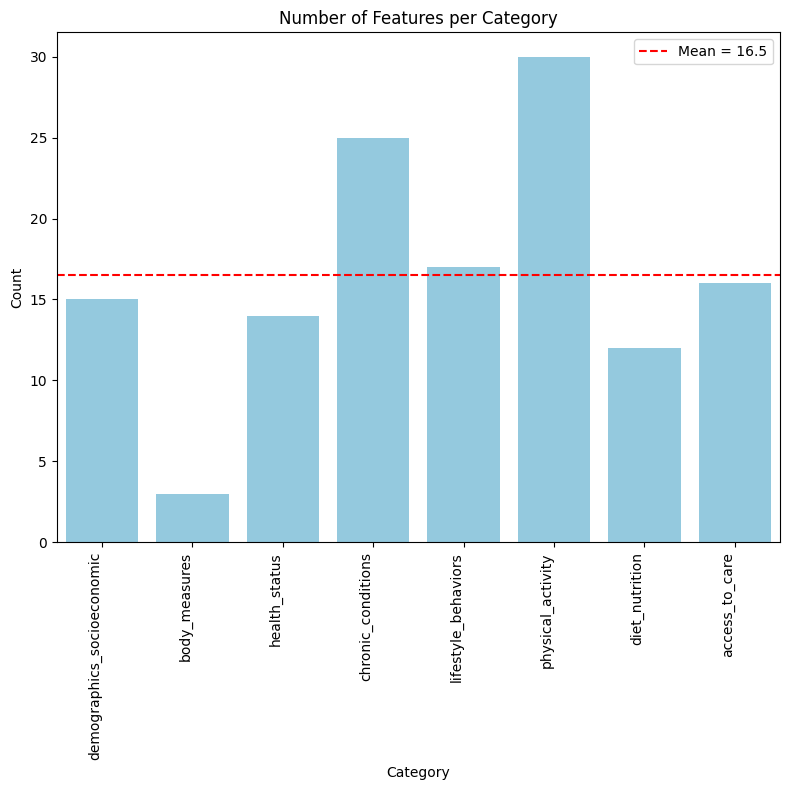

In [20]:
# number of features per category
category_counts = {cat: len(features) for cat, features in feature_clusters.items()}
cats = list(category_counts.keys())
counts = list(category_counts.values())
plot_path = os.path.join(plots_categories_dir, "features_per_category.png")

mean_val = np.mean(counts)
plt.figure(figsize=(8, 8))
sns.barplot(x=cats, y=counts, color="skyblue")
plt.axhline(mean_val, color="red", linestyle="--", label=f"Mean = {mean_val:.1f}")
plt.title("Number of Features per Category")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=90, ha="right")
plt.legend()
plt.tight_layout()
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

## Missing vals

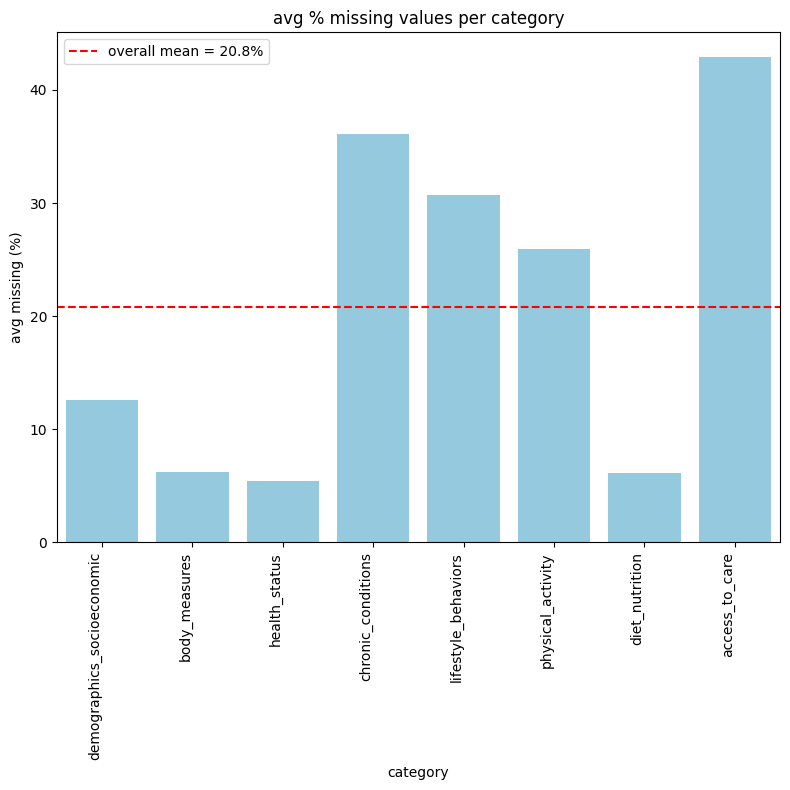

In [21]:
# % missing per var (reduced set)
missing_perc = np.mean(np.isnan(x_train_reduced), axis=0) * 100  
feature_to_cat = {f: c for c, feats in feature_clusters.items() for f in feats}

# group by category and avg
cat_missing = {
    c: np.mean([missing_perc[x_indices_reduced[f]] for f in feats if f in x_indices_reduced])
    for c, feats in feature_clusters.items()
}

cats = list(cat_missing.keys())
avg_missing = list(cat_missing.values())


plt.figure(figsize=(8, 8))
sns.barplot(x=cats, y=avg_missing, color="skyblue")
plt.axhline(np.mean(avg_missing), color="red", ls="--",
            label=f"overall mean = {np.mean(avg_missing):.1f}%")
plt.title("avg % missing values per category")
plt.xlabel("category")
plt.ylabel("avg missing (%)")
plt.xticks(rotation=90, ha="right")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "categories", "missing_values_per_category.png"),
            dpi=300, bbox_inches="tight")
plt.show()


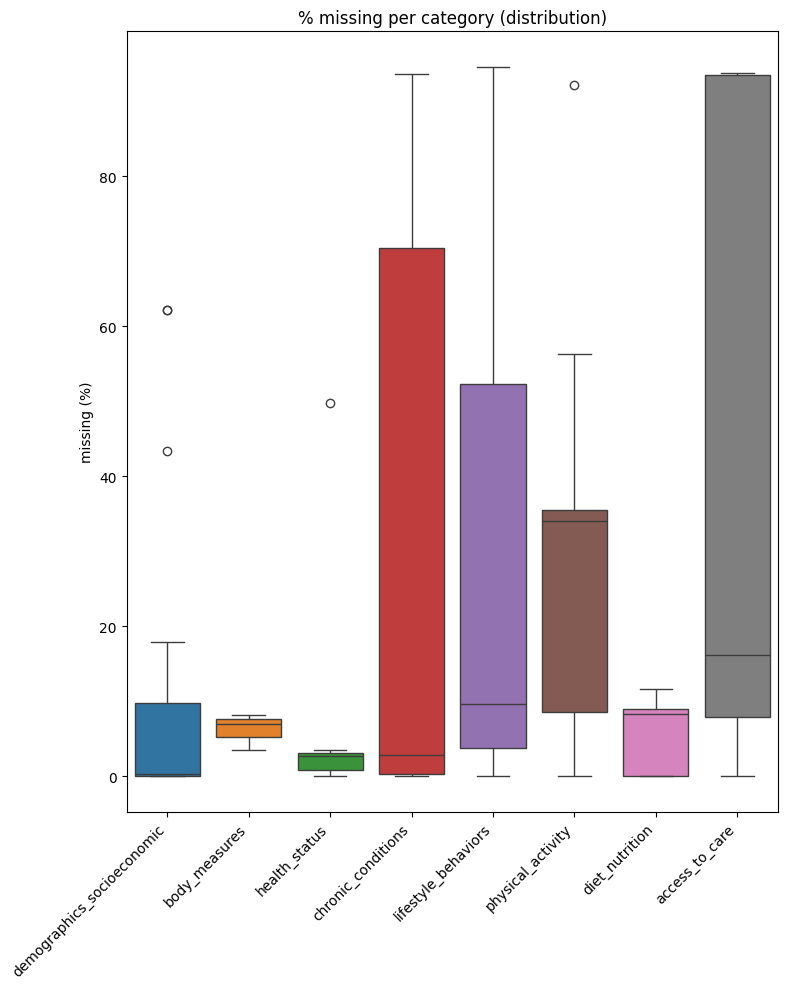

In [22]:
# boxplot of missing distrib per category
data_box = []
for c, feats in feature_clusters.items():
    vals = [missing_perc[x_indices_reduced[f]] for f in feats if f in x_indices_reduced]
    data_box.append(vals)

plt.figure(figsize=(8, 10))
sns.boxplot(data=data_box)
plt.xticks(ticks=range(len(cats)), labels=cats, rotation=45, ha="right")
plt.ylabel("missing (%)")
plt.title("% missing per category (distribution)")
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "categories", "missing_values_box.png"),
            dpi=300, bbox_inches="tight")
plt.show()


Missing value statistics per category

demographics_socioeconomic  mean=12.60%  std=22.44%  min= 0.00%  max=62.17%  median= 0.39%  iqr= 9.76%  >50%=2
body_measures              mean= 6.24%  std= 2.03%  min= 3.46%  max= 8.25%  median= 7.01%  iqr= 2.39%  >50%=0
health_status              mean= 5.43%  std=12.37%  min= 0.00%  max=49.80%  median= 2.69%  iqr= 2.35%  >50%=0
chronic_conditions         mean=36.12%  std=39.95%  min= 0.00%  max=93.64%  median= 2.89%  iqr=70.12%  >50%=11
lifestyle_behaviors        mean=30.72%  std=34.62%  min= 0.00%  max=94.58%  median= 9.64%  iqr=48.48%  >50%=7
physical_activity          mean=25.96%  std=21.01%  min= 0.00%  max=92.13%  median=33.99%  iqr=26.92%  >50%=3
diet_nutrition             mean= 6.12%  std= 4.42%  min= 0.00%  max=11.67%  median= 8.35%  iqr= 9.05%  >50%=0
access_to_care             mean=42.94%  std=41.06%  min= 0.00%  max=93.82%  median=16.16%  iqr=85.57%  >50%=7


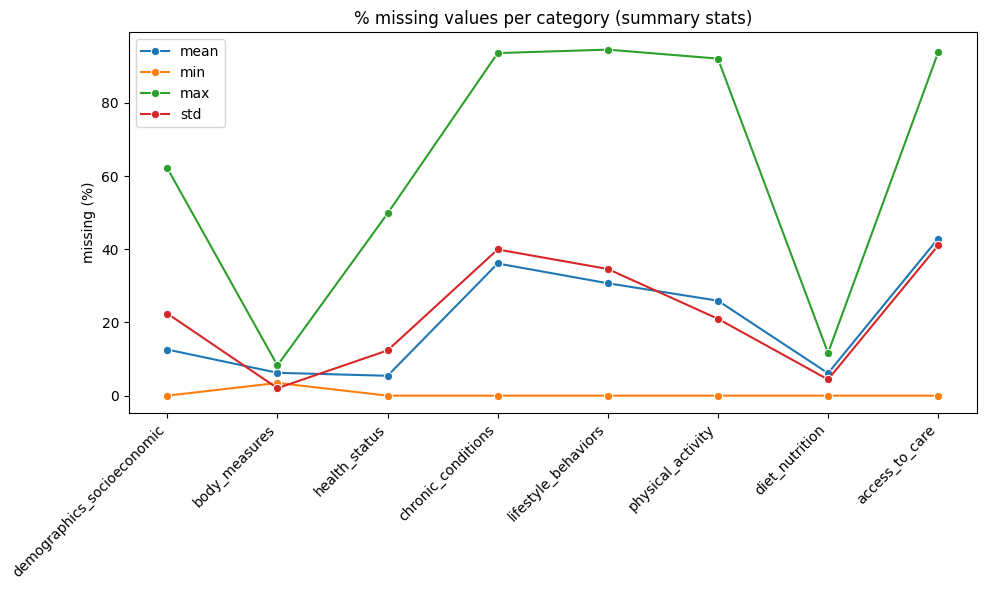

In [23]:
# % missing per feature
missing_perc = np.mean(np.isnan(x_train_reduced), axis=0) * 100

# compute stats per category
cat_names, mean_vals, std_vals, min_vals, max_vals = [], [], [], [], []
med_vals, iqr_vals, count_above_50 = [], [], []

for c, feats in feature_clusters.items():
    vals = [missing_perc[x_indices_reduced[f]] for f in feats if f in x_indices_reduced]
    if len(vals) == 0:
        continue
    vals = np.array(vals)
    cat_names.append(c)
    mean_vals.append(np.mean(vals))
    std_vals.append(np.std(vals))
    min_vals.append(np.min(vals))
    max_vals.append(np.max(vals))
    med_vals.append(np.median(vals))
    iqr_vals.append(np.percentile(vals, 75) - np.percentile(vals, 25))
    count_above_50.append(np.sum(vals > 50))

print("\nMissing value statistics per category\n")
for i, c in enumerate(cat_names):
    print(f"{c:25s}  mean={mean_vals[i]:5.2f}%  std={std_vals[i]:5.2f}%  "
          f"min={min_vals[i]:5.2f}%  max={max_vals[i]:5.2f}%  "
          f"median={med_vals[i]:5.2f}%  iqr={iqr_vals[i]:5.2f}%  "
          f">50%={int(count_above_50[i])}")

# plot mean/min/max/std
plt.figure(figsize=(10, 6))
sns.lineplot(x=cat_names, y=mean_vals, marker="o", label="mean")
sns.lineplot(x=cat_names, y=min_vals, marker="o", label="min")
sns.lineplot(x=cat_names, y=max_vals, marker="o", label="max")
sns.lineplot(x=cat_names, y=std_vals, marker="o", label="std")
plt.xticks(rotation=45, ha="right")
plt.ylabel("missing (%)")
plt.title("% missing values per category (summary stats)")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "categories", "missing_values_summary.png"),
            dpi=300, bbox_inches="tight")
plt.show()


## Correlation per category

In [24]:
len(feature_clusters)

8

### Plots

Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\corr\corr_demographics_socioeconomic.png
Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\corr\corr_body_measures.png
Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\corr\corr_health_status.png
Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\corr\corr_lifestyle_behaviors.png
Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\corr\corr_physical_activity.png
Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\corr\corr_diet_nutrition.png
Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning

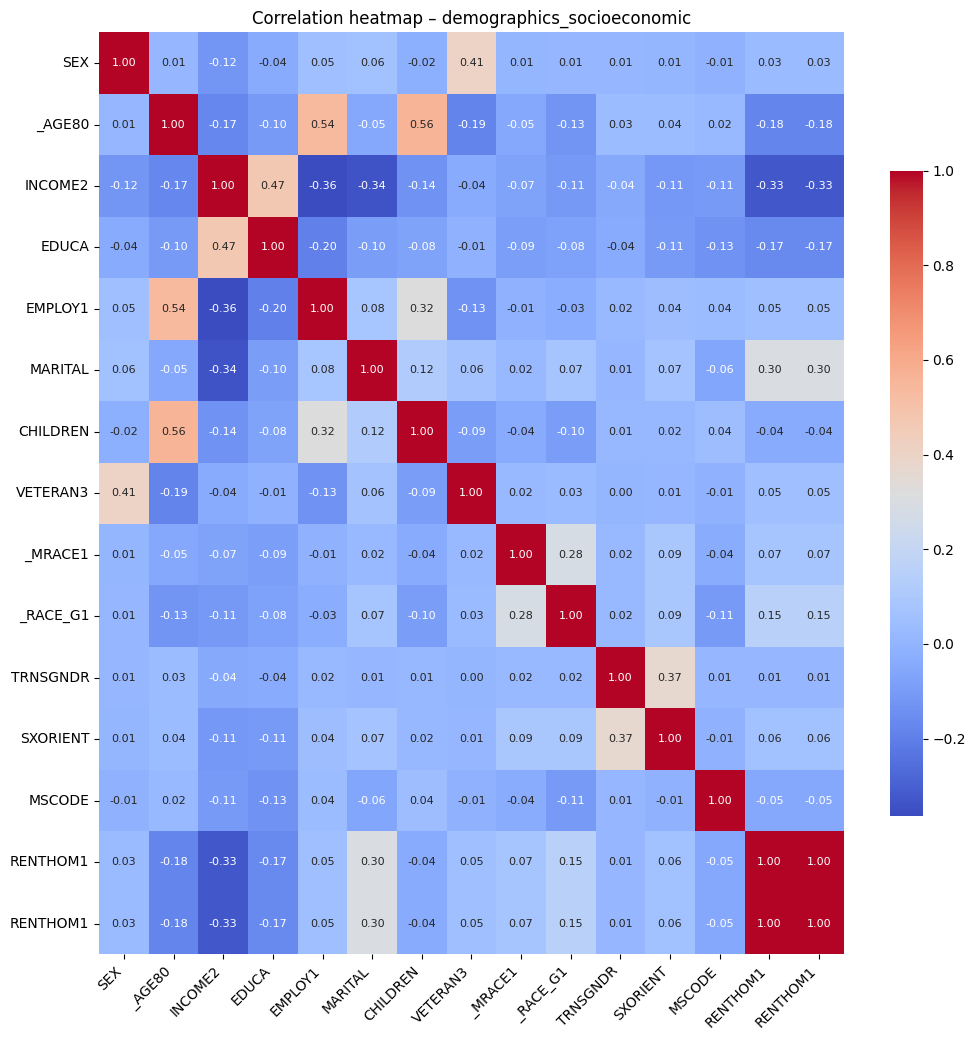

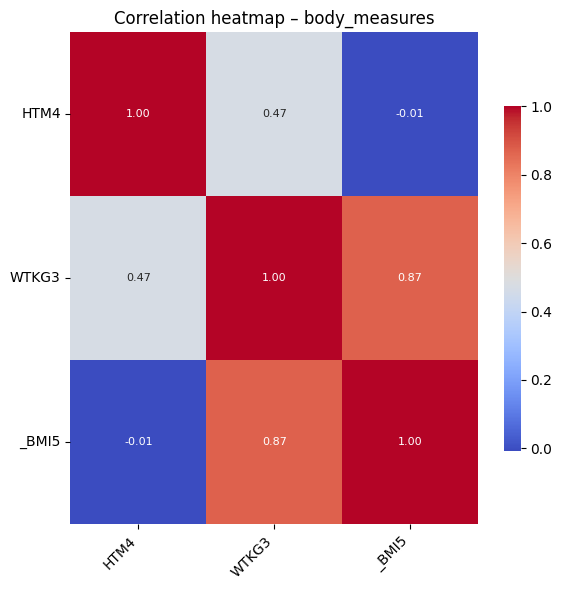

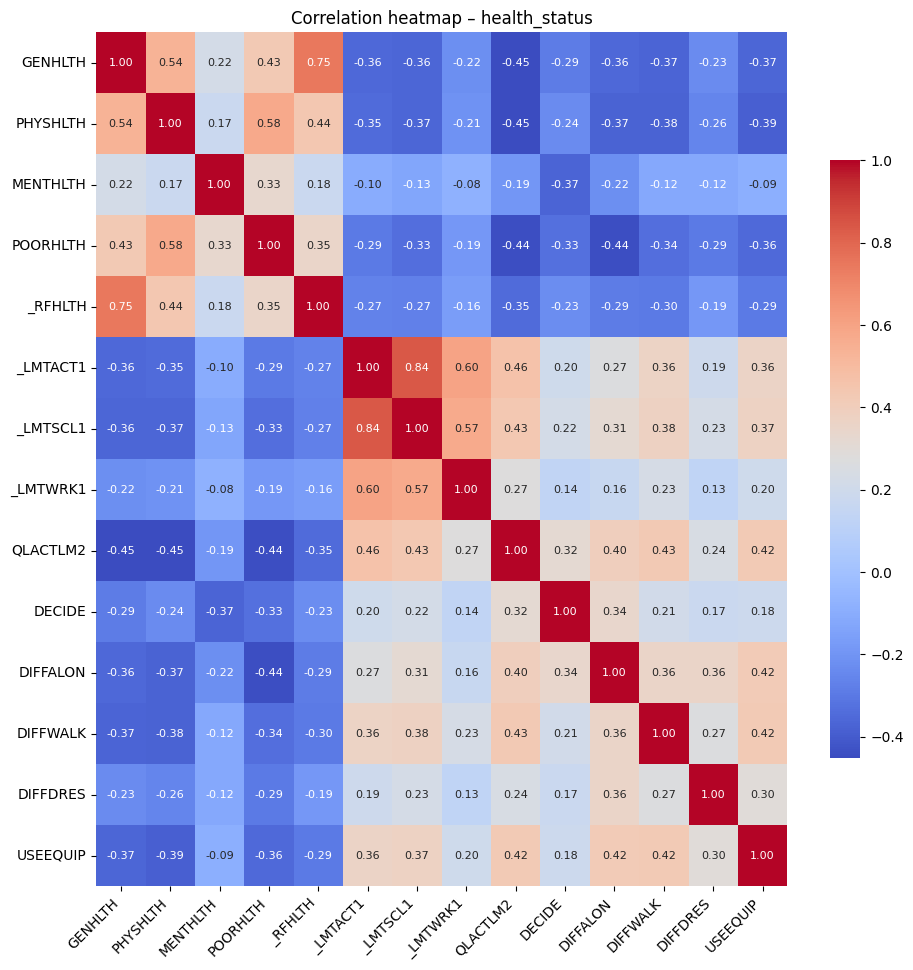

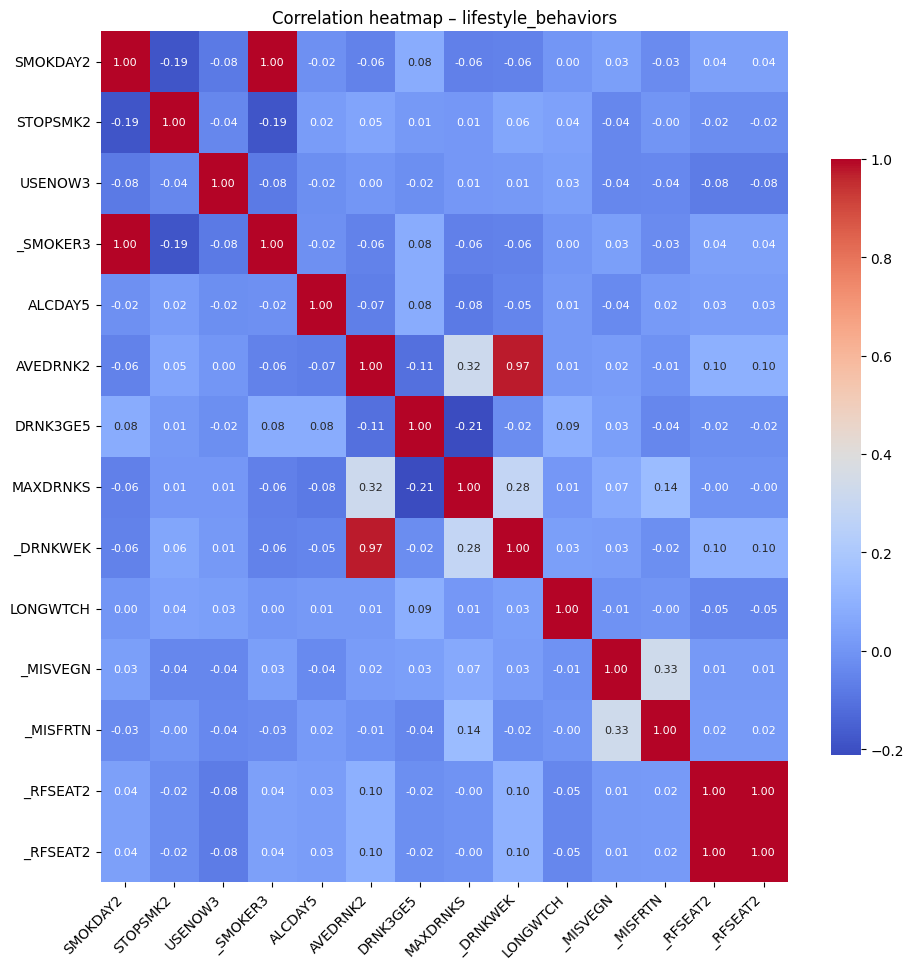

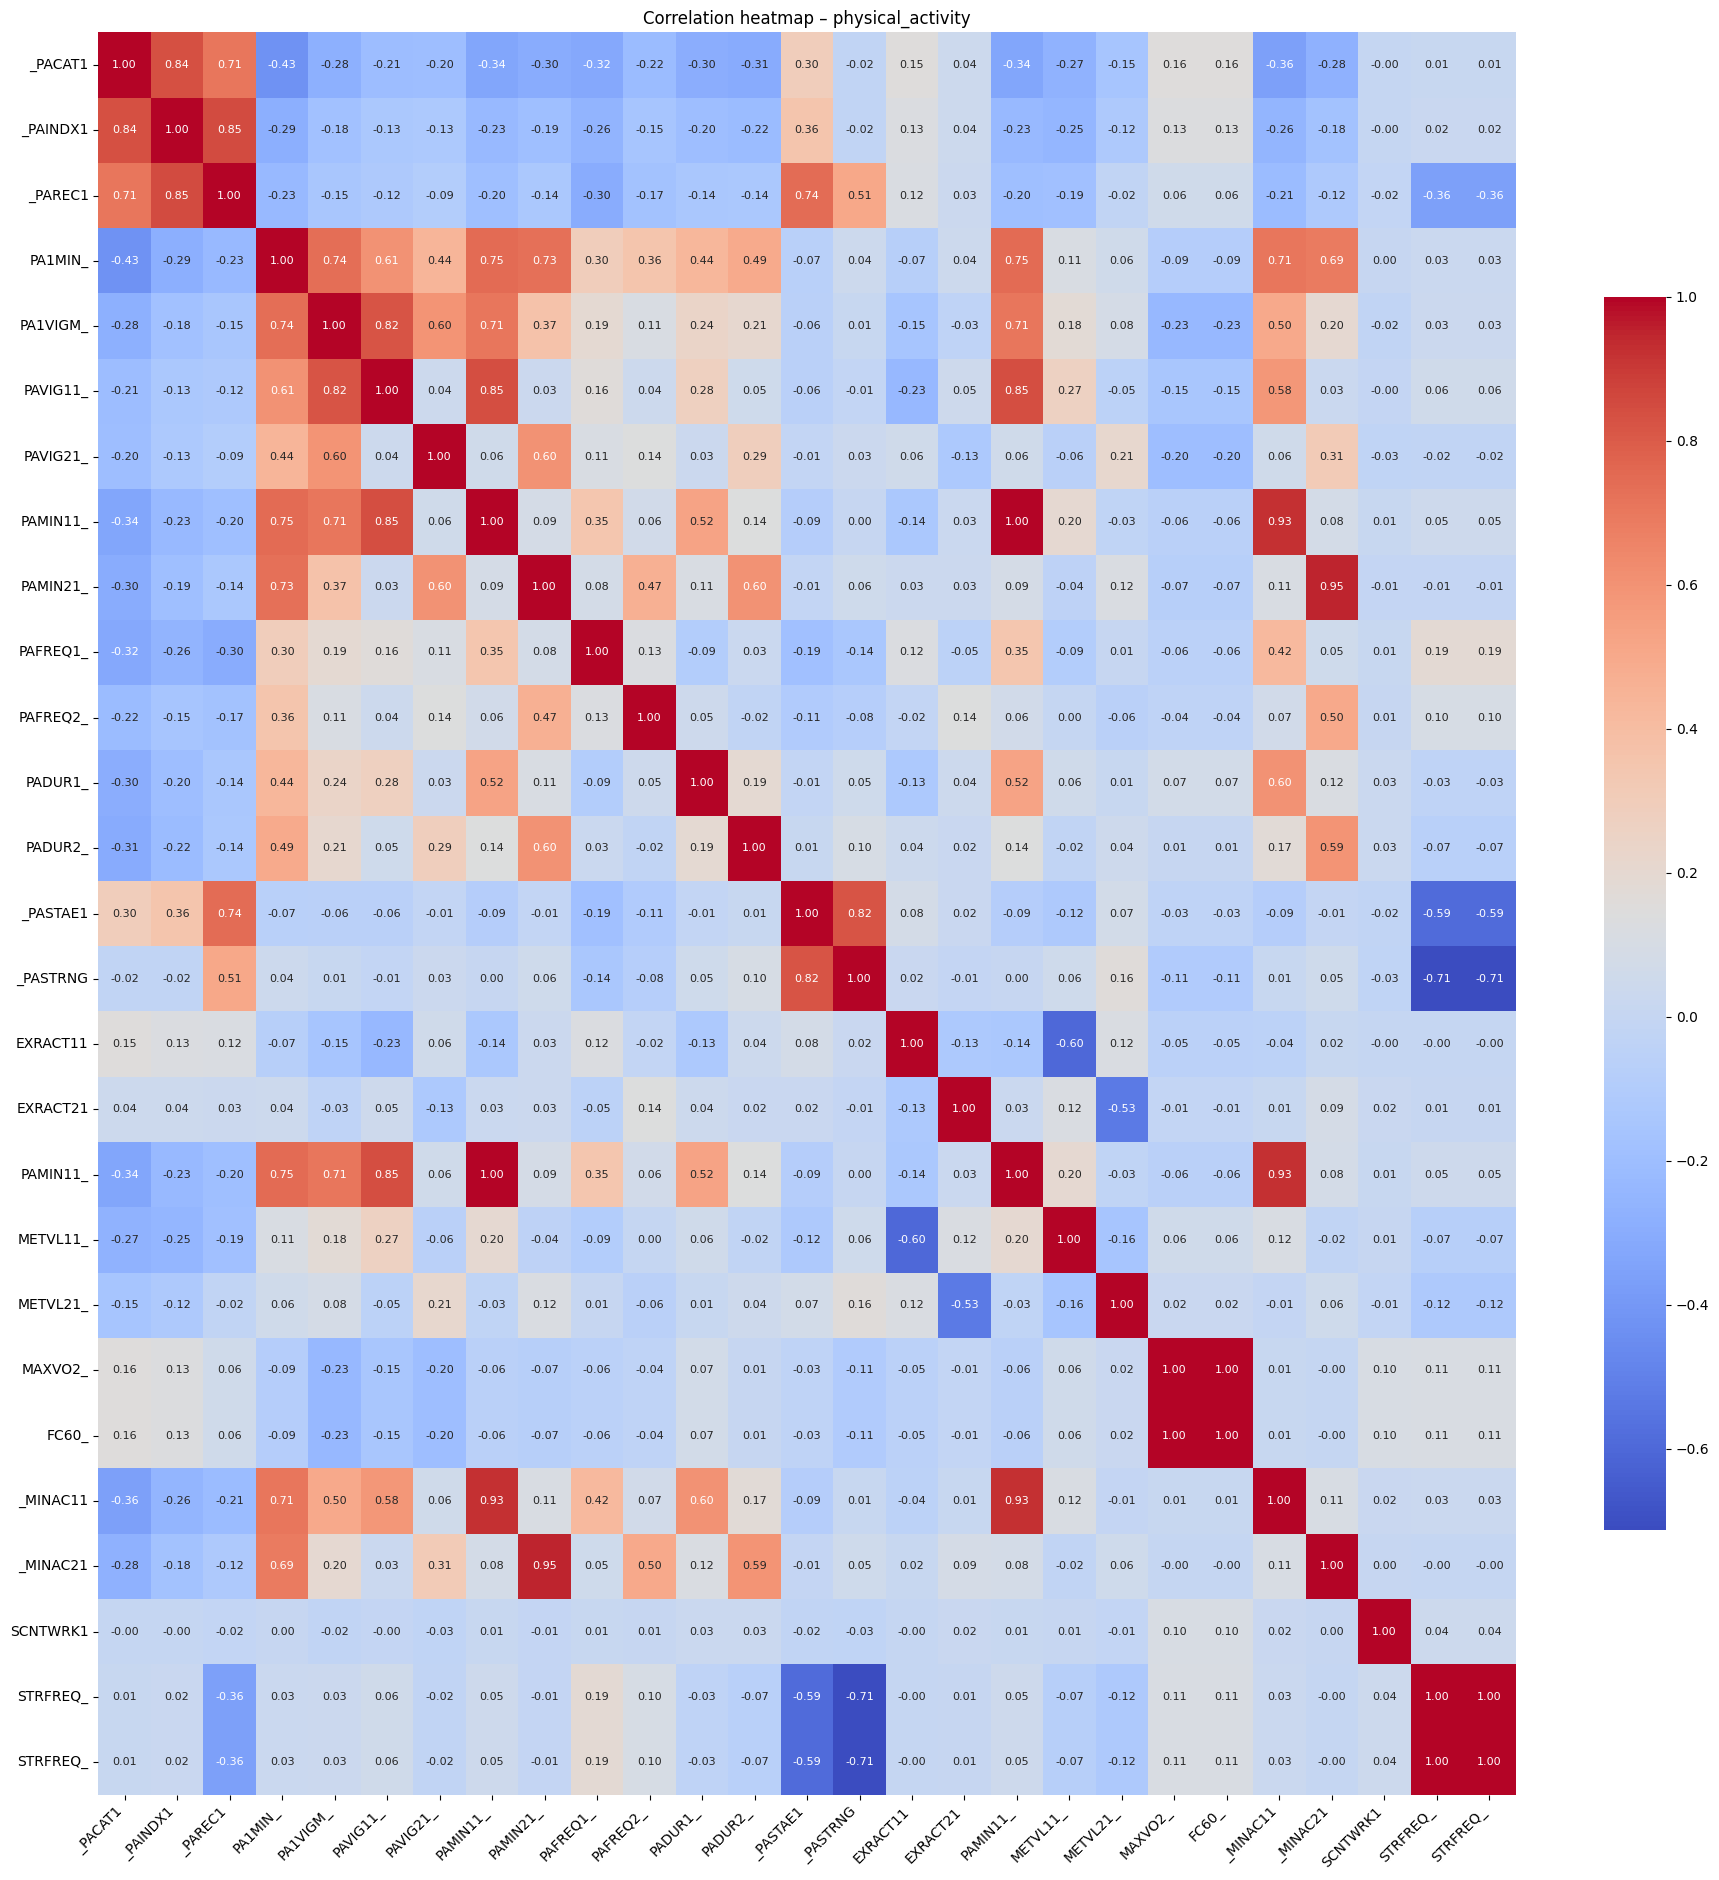

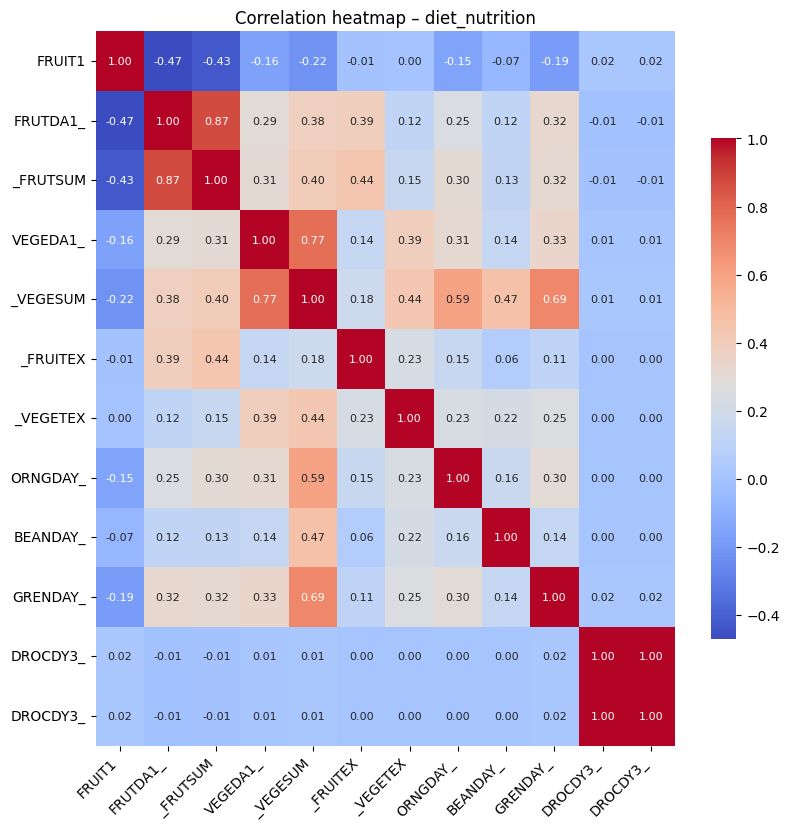

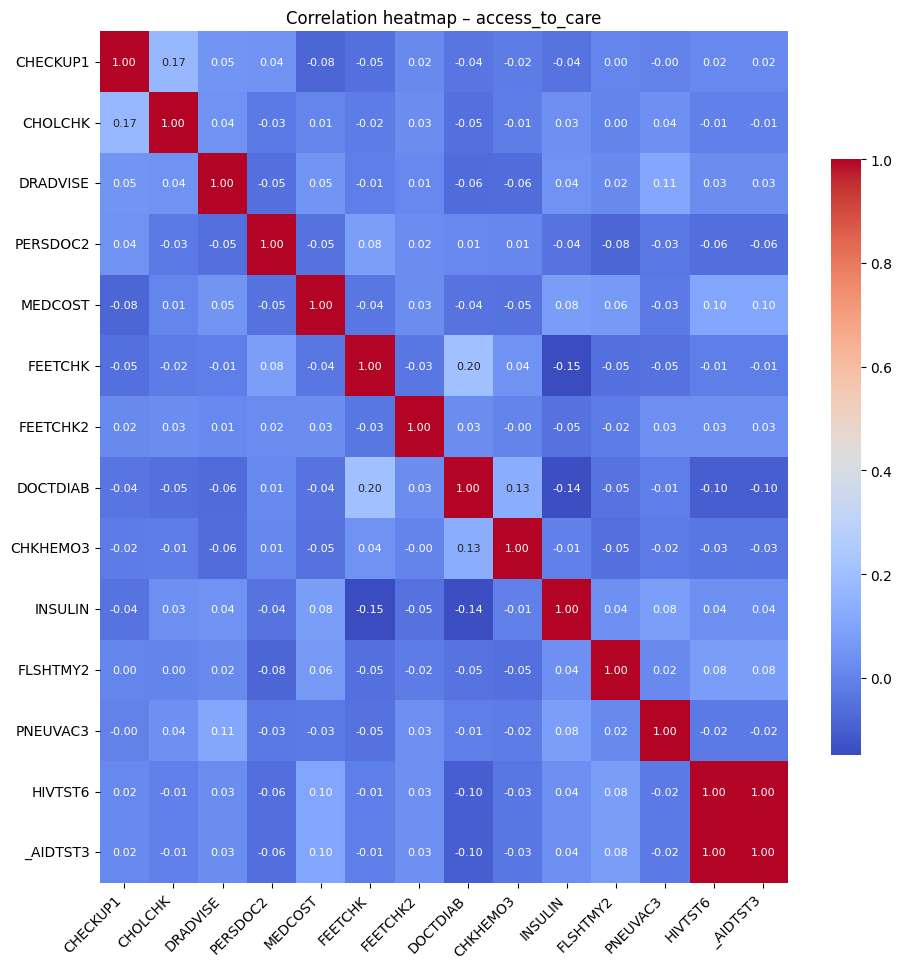

In [25]:
# folder for saving
cat_corr_dir = os.path.join(plots_dir, "categories", "corr")
os.makedirs(cat_corr_dir, exist_ok=True)

# loop over categories
for c, feats in feature_clusters.items():
    idxs = [x_indices_reduced[f] for f in feats if f in x_indices_reduced]
    if len(idxs) < 2:
        continue  # skip single-feature categories

    # subset data
    data_cat = x_train_reduced[:, idxs]

    # remove rows with NaN in any of these features
    mask = ~np.isnan(data_cat).any(axis=1)
    data_clean = data_cat[mask]

    # skip if too few valid rows
    if data_clean.shape[0] < 5:
        continue

    # drop constant cols (avoid zero std → divide by zero)
    stds = np.nanstd(data_clean, axis=0)
    valid_cols = stds > 0
    data_valid = data_clean[:, valid_cols]
    feats_valid = [f for f, keep in zip(feats, valid_cols) if keep]

    if data_valid.shape[1] < 2:
        print(f"Skipping {c}: not enough non-constant features.")
        continue

    # compute correlation
    corr = np.corrcoef(data_valid, rowvar=False)

    # dynamic color range for visibility
    vmin = np.nanmin(corr)
    vmax = np.nanmax(corr)
    if vmin == vmax:  # all identical
        vmin, vmax = -1, 1

    # plot size (scale with number of features)
    n = len(feats_valid)
    fig_size = max(6, 0.7 * n)
    plt.figure(figsize=(fig_size, fig_size))

    # create heatmap with annotations
    sns.heatmap(
        corr,
        vmin=vmin, vmax=vmax,
        cmap="coolwarm",
        annot=True, fmt=".2f", annot_kws={"size": 8},
        xticklabels=feats_valid, yticklabels=feats_valid,
        cbar_kws={"shrink": 0.7}
    )
    plt.title(f"Correlation heatmap – {c}")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()

    # save + show
    save_path = os.path.join(cat_corr_dir, f"corr_{c}.png")
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    # plt.show()

    print(f"Saved: {save_path}")

In [26]:
# inspect variance & missingness per feature for chronic_conditions
target_cat = "chronic_conditions"
feats = feature_clusters[target_cat]
idxs = [x_indices_reduced[f] for f in feats if f in x_indices_reduced]

data_cat = x_train_reduced[:, idxs]
mask = ~np.isnan(data_cat).any(axis=1)
data_clean = data_cat[mask]

print(f"\n=== Category: {target_cat} ===")
print(f"Original features: {len(feats)}")
print(f"After dropping NaNs: {data_clean.shape[0]} samples remain\n")

for f, idx in zip(feats, idxs):
    vals = x_train_reduced[:, idx]
    non_missing = np.sum(~np.isnan(vals))
    unique_vals = np.unique(vals[~np.isnan(vals)])
    std = np.nanstd(vals)
    print(f"{f:15s} | non-missing={non_missing:5d} | unique={len(unique_vals):3d} | std={std:8.4f}")
    if len(unique_vals) <= 3:
        print(f"   values: {unique_vals}")

print("\nCheck if any column has zero variance:")
const_cols = [f for f, idx in zip(feats, idxs) if np.nanstd(x_train_reduced[:, idx]) == 0]
print(f"Constant columns: {const_cols if const_cols else 'None'}")



=== Category: chronic_conditions ===
Original features: 25
After dropping NaNs: 0 samples remain

_ASTHMS1        | non-missing=328135 | unique=  4 | std=  0.7904
_CASTHM1        | non-missing=328135 | unique=  3 | std=  0.7237
   values: [1. 2. 9.]
CHCCOPD1        | non-missing=326588 | unique=  2 | std=  0.2716
   values: [1. 2.]
CHCKIDNY        | non-missing=327158 | unique=  2 | std=  0.1841
   values: [1. 2.]
CHCSCNCR        | non-missing=328134 | unique=  4 | std=  0.3909
CHCOCNCR        | non-missing=328135 | unique=  4 | std=  0.3816
CVDSTRK3        | non-missing=328135 | unique=  4 | std=  0.3122
DIABETE3        | non-missing=328130 | unique=  6 | std=  0.7134
PREDIAB1        | non-missing=61232 | unique=  3 | std=  0.6136
   values: [1. 2. 3.]
DOCTDIAB        | non-missing=20950 | unique= 45 | std=  4.5584
DIABAGE2        | non-missing=41897 | unique= 96 | std= 18.0010
INSULIN         | non-missing=21710 | unique=  3 | std=  0.5243
   values: [1. 2. 9.]
FEETCHK         | non

- **Total features:** 25  
- **Complete rows:** 0 (after removing NaNs)

No single ROW in this category has valid (non NA) values accross all 25 features in this category simultaneously.

When computing the correlation matrix, we initially dropped any row containing a missing value.  Since different features are missing for different participants, this left **zero rows**, making correlation computation impossible.  


- **Variable characteristics:**  
  - Most features are **binary or small categorical codes** (`1/2`, sometimes `9` = missing/unknown).  
  - A few are **quantitative** (`DIABAGE2`, `DOCTDIAB`, `FEETCHK`, `FEETCHK2`) with high variability but very sparse coverage.  
  - None are constant - all have non-zero variance within their valid subsets.  
- **Missingness pattern:** highly unaligned - different variables are missing for different people, preventing any complete-case overlap.  
- **Consequence:** the default correlation method (`np.corrcoef` on complete rows) cannot compute correlations for this category.  
- **Fix / next step:**  
  - Use **pairwise correlation**, computing each pair’s correlation using only rows where both features are non-missing.  
  - This allows estimation of correlations even when full overlap across all features doesn’t exist.  
  - The resulting correlation matrix will contain some NaNs (where pairs have no valid overlap) but will still provide insight into variable relationships within the category.

In [27]:
def pairwise_corr_matrix(data):
    n = data.shape[1]
    corr = np.full((n, n), np.nan)
    for i in range(n):
        for j in range(n):
            valid = ~np.isnan(data[:, i]) & ~np.isnan(data[:, j])
            if np.sum(valid) > 2:
                corr[i, j] = np.corrcoef(data[valid, i], data[valid, j])[0, 1]
    return corr


In [28]:
target_cat = "chronic_conditions"
feats = feature_clusters[target_cat]
idxs = [x_indices_reduced[f] for f in feats if f in x_indices_reduced]

data_cat = x_train_reduced[:, idxs]

c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\venv_ml\Lib\site-packages\numpy\lib\_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\venv_ml\Lib\site-packages\numpy\lib\_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


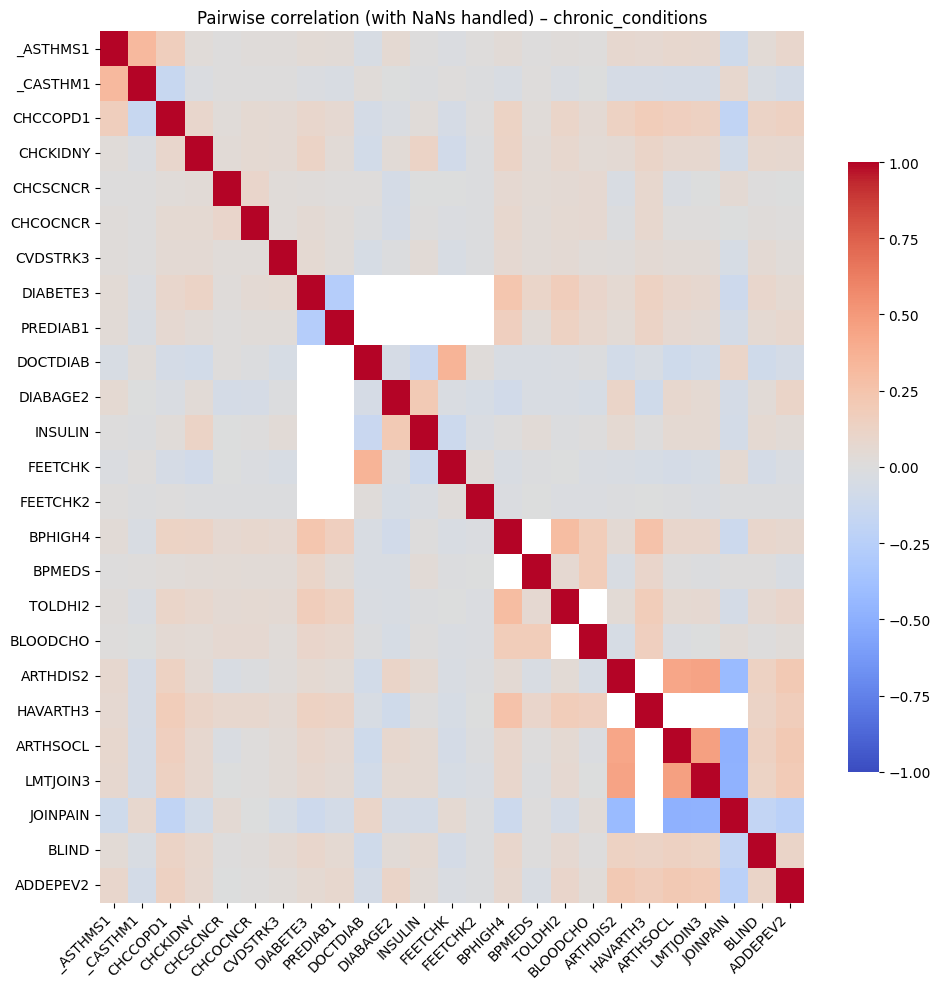

In [29]:
corr_pw = pairwise_corr_matrix(data_cat)

plt.figure(figsize=(10, 10))
sns.heatmap(
    corr_pw, vmin=-1, vmax=1, cmap="coolwarm",
    xticklabels=feats, yticklabels=feats,
    cbar_kws={"shrink": 0.7}, annot=False
)
plt.title("Pairwise correlation (with NaNs handled) – chronic_conditions")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
save_path = os.path.join(cat_corr_dir, f"corr_chronic_conditions.png")
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

In [30]:
# print summary stats
num_valid = np.sum(~np.isnan(corr_pw))
print(f"Non-NaN correlations: {num_valid}/{corr_pw.size} ({100*num_valid/corr_pw.size:.1f}%)")

Non-NaN correlations: 593/625 (94.9%)


### Pairwise correlations

In [31]:
def compute_corr_pairs(X, names):
    """Compute pairwise correlations ignoring NaNs (no self corr)."""
    n = len(names)
    pairs = []
    for i in range(n):
        for j in range(i + 1, n):
            x_i, x_j = X[:, i], X[:, j]
            mask = ~np.isnan(x_i) & ~np.isnan(x_j)
            if mask.sum() > 1:
                r = np.corrcoef(x_i[mask], x_j[mask])[0, 1]
                pairs.append((names[i], names[j], r))
    return pairs


corr_thr = 0.6
top_k = 10
out_path = os.path.join(save_dir, "cluster_corr_summary.txt")

with open(out_path, "w", encoding="utf-8") as f:
    for cat, feats in feature_clusters.items():
        # keep only existing features
        valid_feats = [f for f in feats if f in reduced_feature_set]
        if len(valid_feats) < 2:
            msg = f"\n=== {cat.upper()} ===\nnot enough valid features\n"
            print(msg, end="")
            f.write(msg)
            continue

        # extract cols
        idx = [reduced_feature_set.index(f) for f in valid_feats]
        X = x_train_reduced[:, idx]

        # compute correlations
        pairs = compute_corr_pairs(X, valid_feats)
        if not pairs:
            msg = f"\n=== {cat.upper()} ===\nno valid pairs (all NaN)\n"
            print(msg, end="")
            f.write(msg)
            continue

        # sort and filter
        pairs.sort(key=lambda x: abs(x[2]), reverse=True)
        high_corr = [p for p in pairs if abs(p[2]) > corr_thr]
        top = pairs[:min(top_k, len(pairs))]

        # print results
        header = f"\n=== {cat.upper()} ===\n"
        stats = f"pairs |r| > {corr_thr}: {len(high_corr)}\n"
        print(header + stats, end="")
        f.write(header + stats)

        for a, b, r in top:
            line = f"{a:<15} <---->   {b:<15}  r={r:+.3f}\n"
            print(line, end="")
            f.write(line)


=== DEMOGRAPHICS_SOCIOECONOMIC ===
pairs |r| > 0.6: 1
RENTHOM1        <---->   RENTHOM1         r=+1.000
_AGE80          <---->   EMPLOY1          r=+0.488
_AGE80          <---->   CHILDREN         r=+0.476
TRNSGNDR        <---->   SXORIENT         r=+0.458
INCOME2         <---->   EDUCA            r=+0.452
MARITAL         <---->   RENTHOM1         r=+0.384
MARITAL         <---->   RENTHOM1         r=+0.384
_AGE80          <---->   RENTHOM1         r=-0.352
_AGE80          <---->   RENTHOM1         r=-0.352
INCOME2         <---->   EMPLOY1          r=-0.335

=== BODY_MEASURES ===
pairs |r| > 0.6: 1
WTKG3           <---->   _BMI5            r=+0.871
HTM4            <---->   WTKG3            r=+0.469
HTM4            <---->   _BMI5            r=-0.007

=== HEALTH_STATUS ===
pairs |r| > 0.6: 3
_LMTACT1        <---->   _LMTSCL1         r=+0.827
_LMTSCL1        <---->   _LMTWRK1         r=+0.785
GENHLTH         <---->   _RFHLTH          r=+0.681
_LMTACT1        <---->   _LMTWRK1         r=+

c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\venv_ml\Lib\site-packages\numpy\lib\_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\venv_ml\Lib\site-packages\numpy\lib\_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]



=== CHRONIC_CONDITIONS ===
pairs |r| > 0.6: 0
_ASTHMS1        <---->   _CASTHM1         r=+0.328
DIABETE3        <---->   PREDIAB1         r=-0.271
CHCCOPD1        <---->   JOINPAIN         r=-0.192
CHCCOPD1        <---->   HAVARTH3         r=+0.187
_ASTHMS1        <---->   CHCCOPD1         r=+0.165
CHCCOPD1        <---->   ARTHSOCL         r=+0.158
_CASTHM1        <---->   CHCCOPD1         r=-0.151
CHCCOPD1        <---->   ADDEPEV2         r=+0.145
CHCCOPD1        <---->   LMTJOIN3         r=+0.141
CHCCOPD1        <---->   ARTHDIS2         r=+0.134

=== LIFESTYLE_BEHAVIORS ===
pairs |r| > 0.6: 10
SMOKE100        <---->   SMOKDAY2         r=+nan
SMOKE100        <---->   STOPSMK2         r=+nan
SMOKDAY2        <---->   _SMOKER3         r=+1.000
SMOKE100        <---->   _SMOKER3         r=+0.813
SMOKDAY2        <---->   STOPSMK2         r=-0.256
STOPSMK2        <---->   _SMOKER3         r=-0.256
SMOKDAY2        <---->   DRNK3GE5         r=+0.185
_SMOKER3        <---->   DRNK3GE5        

DEMOGRAPHICS_SOCIOECONOMIC
- Only one high correlation (|r| > 0.6): `RENTHOM1` with itself — irrelevant, ignore.
- Moderate correlations (0.4–0.5) among `_AGE80`, `EMPLOY1`, `CHILDREN`, `INCOME2`, `EDUCA`.
- These make sense socioeconomically (age ↔ employment, income ↔ education).
- No pair strong enough to justify dropping; keep all for now.


BODY_MEASURES
- Strong correlation: `WTKG3` ↔ `_BMI5` (r = 0.87).
- `BMI` is derived from height & weight → redundant.
- **Keep `_BMI5`** (standardized indicator), **drop `WTKG3`**.
- `HTM4` only weakly correlated, so keep it.


HEALTH_STATUS
- `_LMTACT1`, `_LMTSCL1`, `_LMTWRK1` are highly correlated (0.78–0.83).
- These likely represent limitations in activity, social, or work domains → overlapping.
- **Keep one representative**, e.g. `_LMTSCL1` (scale-type), drop `_LMTACT1` and `_LMTWRK1`.
- `GENHLTH` moderately correlated with `_RFHLTH` (r = 0.68); both measure general health → keep `GENHLTH`, drop `_RFHLTH`.



CHRONIC_CONDITIONS
- No high correlations (> 0.6).
- All |r| < 0.4 → independent enough.
- **Keep all features**.


LIFESTYLE_BEHAVIORS
- Perfect correlation `SMOKDAY2` ↔ `_SMOKER3` (r = 1.0) → identical info.
- `SMOKE100` ↔ `_SMOKER3` (r = 0.81) also high.
- Suggest **keep `_SMOKER3`** (cleaner aggregated flag) and **drop `SMOKDAY2`** and possibly `SMOKE100`.
- Others are weak → keep.


PHYSICAL_ACTIVITY
- Very high correlations:
  - `EXERANY2` ↔ `_TOTINDA` (r = 1.0)
  - `_PAREC1` ↔ `_PASTAE1` (r = 0.93)
- Both indicate identical or overlapping activity measures.
- **Drop `_TOTINDA`** (redundant with `EXERANY2`) and **drop `_PASTAE1`** (keep `_PAREC1`).
- Other pairs mostly NaN or moderate → keep.


DIET_NUTRITION
- High correlations:
  - `FRUTDA1_` ↔ `_FRUTSUM` (r = 0.88)
  - `VEGEDA1_` ↔ `_VEGESUM` (r = 0.77)
  - `_FRUITEX` ↔ `_VEGETEX` (r = 0.73)
  - `_VEGESUM` ↔ `GRENDAY_` (r = 0.70)
- Suggest **keep aggregate variables** (`_FRUTSUM`, `_VEGESUM`), **drop individual daily counts** (`FRUTDA1_`, `VEGEDA1_`).
- For `_FRUITEX` and `_VEGETEX`, both high and symmetric — keep one, e.g. `_FRUITEX`.



ACCESS_TO_CARE
- No strong correlations (> 0.6); top pair `CHECKUP1` ↔ `CHOLCHK` (r = 0.55).
- These reflect different preventive behaviors.
- **Keep all**; no redundancy.


In [32]:
corr_thr = 0.6
nan_info = {}
to_drop = set()

def nan_percent(x):
    return np.isnan(x).mean() * 100

print("=== Features flagged for high correlation (|r| > 0.6) ===")

for cat, feats in feature_clusters.items():
    valid_feats = [f for f in feats if f in reduced_feature_set]
    if len(valid_feats) < 2:
        continue

    idx = [reduced_feature_set.index(f) for f in valid_feats]
    X = x_train_reduced[:, idx]

    pairs = compute_corr_pairs(X, valid_feats)
    for a, b, r in pairs:
        if np.isnan(r) or abs(r) <= corr_thr:
            continue

        # compute NaN %
        nan_a = nan_percent(X[:, valid_feats.index(a)])
        nan_b = nan_percent(X[:, valid_feats.index(b)])

        # store for later
        nan_info[a] = nan_a
        nan_info[b] = nan_b

        # decide which to drop
        drop = a if nan_a > nan_b else b
        to_drop.add(drop)

        print(f"{a:<15} ({nan_a:5.2f}% NaN) <-> {b:<15} ({nan_b:5.2f}% NaN)  r={r:+.3f}  -> drop {drop}")

print("\n=== Suggested features to drop ===")
print(sorted(to_drop))


=== Features flagged for high correlation (|r| > 0.6) ===
RENTHOM1        ( 0.69% NaN) <-> RENTHOM1        ( 0.69% NaN)  r=+1.000  -> drop RENTHOM1
WTKG3           ( 7.01% NaN) <-> _BMI5           ( 8.25% NaN)  r=+0.871  -> drop _BMI5
GENHLTH         ( 0.00% NaN) <-> _RFHLTH         ( 0.00% NaN)  r=+0.681  -> drop GENHLTH
_LMTACT1        ( 3.49% NaN) <-> _LMTSCL1        ( 0.57% NaN)  r=+0.827  -> drop _LMTACT1
_LMTSCL1        ( 0.57% NaN) <-> _LMTWRK1        ( 0.57% NaN)  r=+0.785  -> drop _LMTWRK1
SMOKE100        ( 3.95% NaN) <-> _SMOKER3        ( 4.04% NaN)  r=+0.813  -> drop _SMOKER3
SMOKDAY2        (58.32% NaN) <-> _SMOKER3        ( 4.04% NaN)  r=+1.000  -> drop SMOKDAY2
DRNKANY5        ( 0.00% NaN) <-> ALCDAY5         ( 4.87% NaN)  r=-0.936  -> drop ALCDAY5
DRNKANY5        ( 0.00% NaN) <-> _DRNKWEK        ( 0.00% NaN)  r=+0.852  -> drop _DRNKWEK
DRNKANY5        ( 0.00% NaN) <-> _MISVEGN        ( 0.00% NaN)  r=+0.602  -> drop _MISVEGN
DRNKANY5        ( 0.00% NaN) <-> _MISFRTN      

- keep `PA1MIN_` =  Minutes of total Physical Activity per week.
- I would also keep `_PASTRNG` = Meet or not muscle strengthening recommendations since muscle health could be related ot heart health.
- `_PAREC1` - met or not Aerobic and Strengthening Guideline

In [ ]:
to_drop = [
           "WTKG3", # body measures
           "_RFHLTH", "_LMTACT1", "_LMTWRK1", # health status
           "SMOKDAY2", "_SMOKER3", "AVEDRNK2", "ALCDAY5", "DRNK3GE5", "MAXDRNKS", "STOPSMK2", "WTCHSALT", "_MISFRTN", "_MISVEGN",  # lifestyle behaviors
           '_PASTAE1', '_TOTINDA', "_PAINDX1", "PAMISS1_" , "PAMIN11_", "PAMIN21_", "STRFREQ_", "PAVIG11_", "PAVIG21_", "_MINAC11", "_MINAC21", "FC60_",  # physical activity
            'FRUTDA1_', 'VEGEDA1_', '_VEGETEX', 'GRENDAY_', '_FRUITEX', # diet and nutrition
            'HIVTST6' 
           ]


In [34]:
# find variables that appear twice or more within the same category
to_drop_duplicated = []
for cat, feats in feature_clusters.items():
    seen = set()
    dupes = {f for f in feats if f in seen or seen.add(f)}
    if dupes:
        print(f"{cat}: {dupes}")
        to_drop_duplicated.extend(list(dupes))

# make sure unique
to_drop_duplicated = list(set(to_drop_duplicated))
print("\nFeatures duplicated within a category:", to_drop_duplicated)

demographics_socioeconomic: {'RENTHOM1'}
lifestyle_behaviors: {'_RFSEAT2'}
physical_activity: {'PAMIN11_', 'STRFREQ_'}
diet_nutrition: {'DROCDY3_'}

Features duplicated within a category: ['_RFSEAT2', 'RENTHOM1', 'PAMIN11_', 'STRFREQ_', 'DROCDY3_']


In [35]:
# drop logic: remove all normal to_drop features, but for duplicated ones, drop only one instance
filtered_features = []
seen_dupes = set()
for f in reduced_feature_set:
    if f in to_drop:
        continue
    elif f in to_drop_duplicated:
        if f in seen_dupes:
            filtered_features.append(f)  # keep second (and later) occurrences
        else:
            seen_dupes.add(f)
            continue  # drop the first occurrence only
    else:
        filtered_features.append(f)

# rebuild final dataset
reduced_feature_set_final = filtered_features
x_train_final = x_train_reduced[:, [reduced_feature_set.index(f) for f in reduced_feature_set_final]]

print(f"Final feature count: {len(reduced_feature_set_final)}")

Final feature count: 87


In [36]:
reduced_feature_set_final

['_CASTHM1',
 'FLUSHOT6',
 'METVL11_',
 '_PASTRNG',
 'EDUCA',
 'CHCCOPD1',
 'DRADVISE',
 'CHCKIDNY',
 'ARTHSOCL',
 'MENTHLTH',
 'SMOKE100',
 'DOCTDIAB',
 'DIABAGE2',
 'VETERAN3',
 'CHKHEMO3',
 'SEX',
 '_DRNKWEK',
 'JOINPAIN',
 'MARITAL',
 'EXERANY2',
 '_PACAT1',
 'INSULIN',
 'DIFFALON',
 'FRUIT1',
 'QLACTLM2',
 'BLIND',
 'PADUR2_',
 'PAFREQ2_',
 'LMTJOIN3',
 'CHOLCHK',
 'POORHLTH',
 'DIABETE3',
 '_FRUTSUM',
 'PERSDOC2',
 'EXRACT21',
 'FEETCHK',
 '_VEGESUM',
 'PNEUVAC3',
 'BPHIGH4',
 'GENHLTH',
 'EXRACT11',
 '_BMI5',
 'DECIDE',
 '_ASTHMS1',
 '_MRACE1',
 '_LMTSCL1',
 'ORNGDAY_',
 'MSCODE',
 'PHYSHLTH',
 'TOLDHI2',
 'PADUR1_',
 'DIFFWALK',
 'BEANDAY_',
 'CHCSCNCR',
 'PAFREQ1_',
 '_AIDTST3',
 'FLSHTMY2',
 'PA1VIGM_',
 'METVL21_',
 'SXORIENT',
 'ARTHDIS2',
 'PA1MIN_',
 'MAXVO2_',
 '_RACE_G1',
 'LONGWTCH',
 'SCNTWRK1',
 'FEETCHK2',
 'EMPLOY1',
 'BLOODCHO',
 'USENOW3',
 'DRNKANY5',
 '_PAREC1',
 'DIFFDRES',
 'USEEQUIP',
 'ADDEPEV2',
 '_AGE80',
 'HTM4',
 'INCOME2',
 'CVDSTRK3',
 'CHCOCNCR',
 'M

Repeat again to see if any high correlations left

In [37]:
def compute_corr_pairs(X, names):
    """Compute pairwise correlations ignoring NaNs (no self corr)."""
    n = len(names)
    pairs = []
    for i in range(n):
        for j in range(i + 1, n):
            x_i, x_j = X[:, i], X[:, j]
            mask = ~np.isnan(x_i) & ~np.isnan(x_j)
            if mask.sum() > 1:
                r = np.corrcoef(x_i[mask], x_j[mask])[0, 1]
                pairs.append((names[i], names[j], r))
    return pairs


# def compute_corr_pairs(X, names, min_valid=100):
#     """Pairwise correlation ignoring NaNs; skips pairs with too few valid points."""
#     n = len(names)
#     pairs = []
#     for i in range(n):
#         for j in range(i + 1, n):
#             x_i, x_j = X[:, i], X[:, j]
#             mask = ~np.isnan(x_i) & ~np.isnan(x_j)
#             if mask.sum() < min_valid:
#                 continue  # too few valid values -> skip
#             if np.std(x_i[mask]) == 0 or np.std(x_j[mask]) == 0:
#                 continue  # constant features -> undefined corr
#             r = np.corrcoef(x_i[mask], x_j[mask])[0, 1]
#             if not np.isnan(r):
#                 pairs.append((names[i], names[j], r))
#     return pairs


corr_thr = 0.6
top_k = 31
out_path = os.path.join(save_dir, "cluster_corr_summary_second.txt")
to_drop_again = set()

with open(out_path, "w", encoding="utf-8") as f:
    for cat, feats in feature_clusters.items() :
    # for cat, feats in [('physical_activity', feature_clusters['physical_activity'])] :
        valid_feats = [f for f in feats if f in reduced_feature_set_final]
        if len(valid_feats) < 2:
            continue

        idx = [reduced_feature_set_final.index(f) for f in valid_feats]
        X = x_train_final[:, idx]

        pairs = compute_corr_pairs(X, valid_feats)
        for a, b, r in pairs:
            if np.isnan(r) or abs(r) <= corr_thr:
                continue

            # compute NaN %
            nan_a = nan_percent(X[:, valid_feats.index(a)])
            nan_b = nan_percent(X[:, valid_feats.index(b)])

            # store for later
            nan_info[a] = nan_a
            nan_info[b] = nan_b

            # decide which to drop
            drop = a if nan_a > nan_b else b
            to_drop_again.add(drop)

            print(f"{a:<15} ({nan_a:5.2f}% NaN) <-> {b:<15} ({nan_b:5.2f}% NaN)  r={r:+.3f}  -> drop {drop}")

    print("\n=== Suggested features to drop ===")
    print(sorted(to_drop_again))

DRNKANY5        ( 0.00% NaN) <-> _DRNKWEK        ( 0.00% NaN)  r=+0.852  -> drop _DRNKWEK
_PACAT1         ( 0.00% NaN) <-> _PAREC1         ( 0.00% NaN)  r=+0.914  -> drop _PAREC1
PA1MIN_         (34.39% NaN) <-> PA1VIGM_        (34.07% NaN)  r=+0.790  -> drop PA1MIN_

=== Suggested features to drop ===
['PA1MIN_', '_DRNKWEK', '_PAREC1']


## Drop dropped from category lists

In [38]:
# drop all features in to_drop from each category list
for name in cats:
    globals()[name] = [f for f in globals()[name] if f in reduced_feature_set_final]

# dictionary update - drop the dropped vars from the values for each key (keys=categories)
feature_clusters = {
    cat: [f for f in feats if f not in to_drop]
    for cat, feats in feature_clusters.items()
}

# define new index mapping for the final feature set
x_indices_final = {f: i for i, f in enumerate(reduced_feature_set_final)}

In [39]:
cats

['demographics_socioeconomic',
 'body_measures',
 'health_status',
 'chronic_conditions',
 'lifestyle_behaviors',
 'physical_activity',
 'diet_nutrition',
 'access_to_care']

In [40]:
for name in cats : 
    print(f"{name} : {globals()[name]}\n")

demographics_socioeconomic : ['SEX', '_AGE80', 'INCOME2', 'EDUCA', 'EMPLOY1', 'MARITAL', 'CHILDREN', 'VETERAN3', '_MRACE1', '_RACE_G1', 'TRNSGNDR', 'SXORIENT', 'MSCODE']

body_measures : ['HTM4', '_BMI5']

health_status : ['GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'POORHLTH', '_LMTSCL1', 'QLACTLM2', 'DECIDE', 'DIFFALON', 'DIFFWALK', 'DIFFDRES', 'USEEQUIP']

chronic_conditions : ['_ASTHMS1', '_CASTHM1', 'CHCCOPD1', 'CHCKIDNY', 'CHCSCNCR', 'CHCOCNCR', 'CVDSTRK3', 'DIABETE3', 'PREDIAB1', 'DOCTDIAB', 'DIABAGE2', 'INSULIN', 'FEETCHK', 'FEETCHK2', 'BPHIGH4', 'BPMEDS', 'TOLDHI2', 'BLOODCHO', 'ARTHDIS2', 'HAVARTH3', 'ARTHSOCL', 'LMTJOIN3', 'JOINPAIN', 'BLIND', 'ADDEPEV2']

lifestyle_behaviors : ['SMOKE100', 'USENOW3', 'DRNKANY5', '_DRNKWEK', 'LONGWTCH']

physical_activity : ['EXERANY2', '_PACAT1', '_PAREC1', 'PA1MIN_', 'PA1VIGM_', 'PAFREQ1_', 'PAFREQ2_', 'PADUR1_', 'PADUR2_', '_PASTRNG', 'EXRACT11', 'EXRACT21', 'METVL11_', 'METVL21_', 'MAXVO2_', 'SCNTWRK1']

diet_nutrition : ['FRUIT1', '_FRUTSUM', '_

# 4. Per category analysis - rerun after dropping high correlated variables

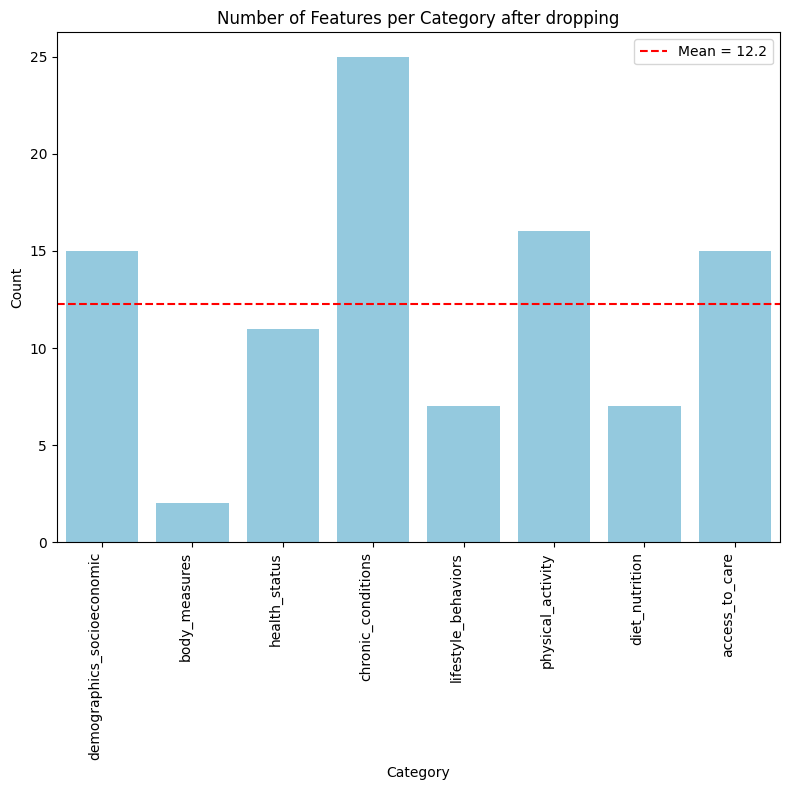

In [41]:
# number of features per category
category_counts = {cat: len(features) for cat, features in feature_clusters.items()}
cats = list(category_counts.keys())
counts = list(category_counts.values())
plot_path = os.path.join(plots_categories_dir, "features_per_category_after_dropping.png")

mean_val = np.mean(counts)
plt.figure(figsize=(8, 8))
sns.barplot(x=cats, y=counts, color="skyblue")
plt.axhline(mean_val, color="red", linestyle="--", label=f"Mean = {mean_val:.1f}")
plt.title("Number of Features per Category after dropping")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=90, ha="right")
plt.legend()
plt.tight_layout()
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

## Missing vals

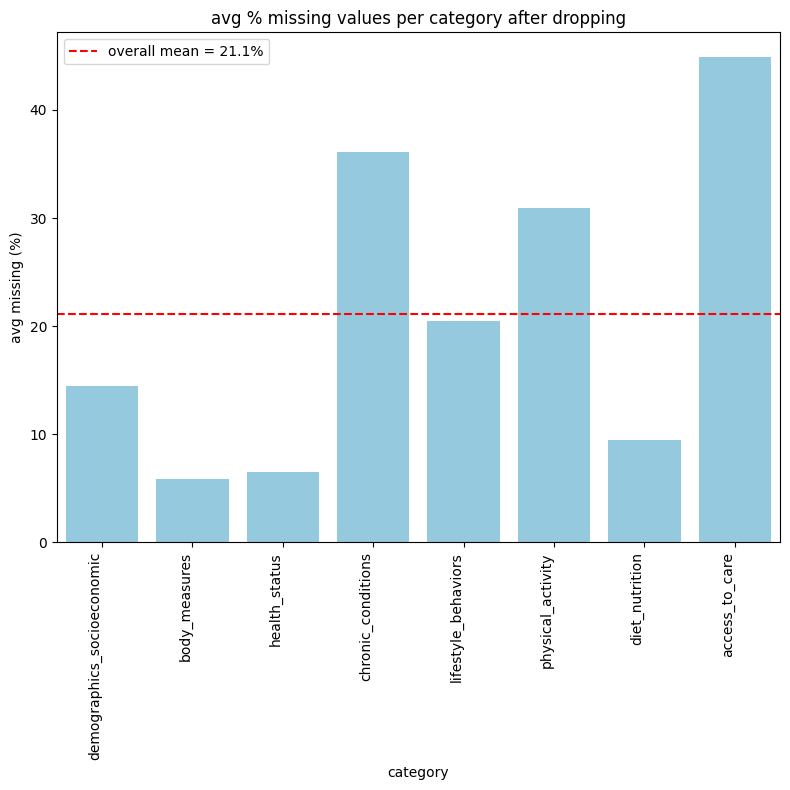

In [42]:
# % missing per var (reduced set)
missing_perc = np.mean(np.isnan(x_train_final), axis=0) * 100  
feature_to_cat = {f: c for c, feats in feature_clusters.items() for f in feats}

# group by category and avg
cat_missing = {
    c: np.mean([missing_perc[x_indices_final[f]] for f in feats if f in x_indices_final])
    for c, feats in feature_clusters.items()
}

cats = list(cat_missing.keys())
avg_missing = list(cat_missing.values())


plt.figure(figsize=(8, 8))
sns.barplot(x=cats, y=avg_missing, color="skyblue")
plt.axhline(np.mean(avg_missing), color="red", ls="--",
            label=f"overall mean = {np.mean(avg_missing):.1f}%")
plt.title("avg % missing values per category after dropping")
plt.xlabel("category")
plt.ylabel("avg missing (%)")
plt.xticks(rotation=90, ha="right")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "categories", "missing_values_per_category_after_dropping.png"),
            dpi=300, bbox_inches="tight")
plt.show()


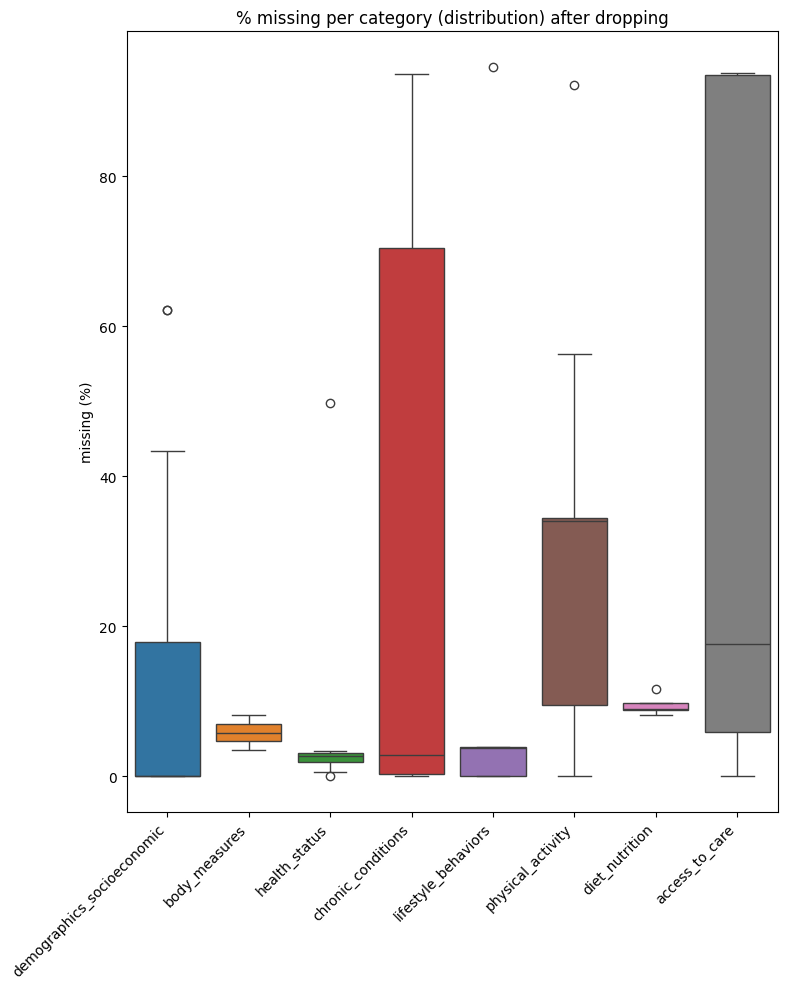

In [43]:
# boxplot of missing distrib per category
data_box = []
for c, feats in feature_clusters.items():
    vals = [missing_perc[x_indices_final[f]] for f in feats if f in x_indices_final]
    data_box.append(vals)

plt.figure(figsize=(8, 10))
sns.boxplot(data=data_box)
plt.xticks(ticks=range(len(cats)), labels=cats, rotation=45, ha="right")
plt.ylabel("missing (%)")
plt.title("% missing per category (distribution) after dropping")
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "categories", "missing_values_box_after_dropping.png"),
            dpi=300, bbox_inches="tight")
plt.show()


Missing value statistics per category after dropping

demographics_socioeconomic  mean=14.43%  std=23.57%  min= 0.00%  max=62.17%  median= 0.00%  iqr=17.86%  >50%=2
body_measures              mean= 5.86%  std= 2.39%  min= 3.46%  max= 8.25%  median= 5.86%  iqr= 2.39%  >50%=0
health_status              mean= 6.54%  std=13.72%  min= 0.00%  max=49.80%  median= 2.79%  iqr= 1.18%  >50%=0
chronic_conditions         mean=36.12%  std=39.95%  min= 0.00%  max=93.64%  median= 2.89%  iqr=70.12%  >50%=11
lifestyle_behaviors        mean=20.46%  std=37.10%  min= 0.00%  max=94.58%  median= 3.79%  iqr= 3.95%  >50%=1
physical_activity          mean=30.90%  std=23.58%  min= 0.00%  max=92.13%  median=33.99%  iqr=24.90%  >50%=3
diet_nutrition             mean= 9.49%  std= 1.20%  min= 8.21%  max=11.67%  median= 8.95%  iqr= 0.96%  >50%=0
access_to_care             mean=44.94%  std=41.65%  min= 0.00%  max=93.82%  median=17.66%  iqr=87.54%  >50%=7


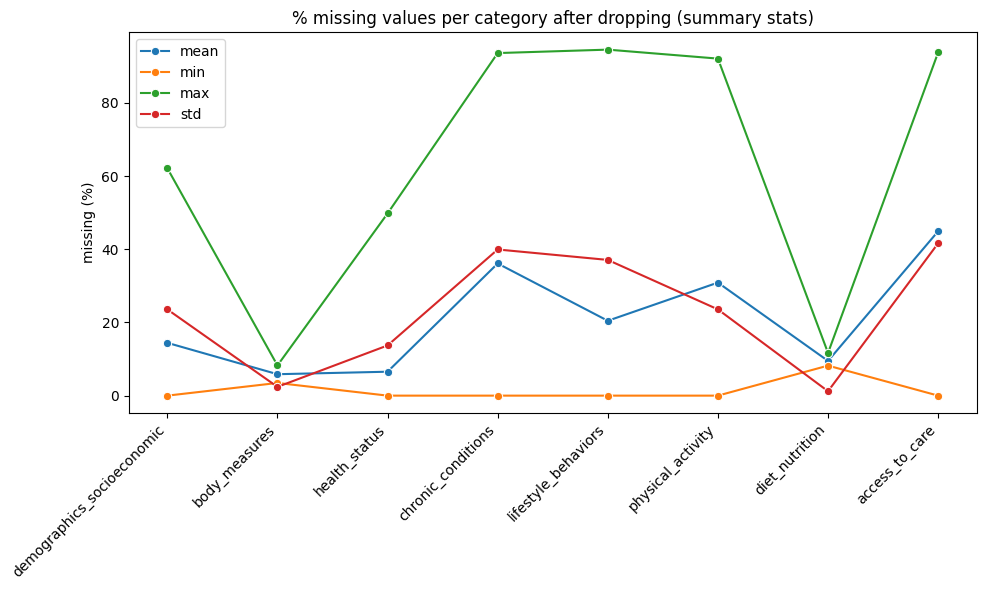

In [44]:
# % missing per feature
missing_perc = np.mean(np.isnan(x_train_final), axis=0) * 100

# compute stats per category
cat_names, mean_vals, std_vals, min_vals, max_vals = [], [], [], [], []
med_vals, iqr_vals, count_above_50 = [], [], []

for c, feats in feature_clusters.items():
    vals = [missing_perc[x_indices_final[f]] for f in feats if f in x_indices_final]
    if len(vals) == 0:
        continue
    vals = np.array(vals)
    cat_names.append(c)
    mean_vals.append(np.mean(vals))
    std_vals.append(np.std(vals))
    min_vals.append(np.min(vals))
    max_vals.append(np.max(vals))
    med_vals.append(np.median(vals))
    iqr_vals.append(np.percentile(vals, 75) - np.percentile(vals, 25))
    count_above_50.append(np.sum(vals > 50))

print("\nMissing value statistics per category after dropping\n")
for i, c in enumerate(cat_names):
    print(f"{c:25s}  mean={mean_vals[i]:5.2f}%  std={std_vals[i]:5.2f}%  "
          f"min={min_vals[i]:5.2f}%  max={max_vals[i]:5.2f}%  "
          f"median={med_vals[i]:5.2f}%  iqr={iqr_vals[i]:5.2f}%  "
          f">50%={int(count_above_50[i])}")

# plot mean/min/max/std
plt.figure(figsize=(10, 6))
sns.lineplot(x=cat_names, y=mean_vals, marker="o", label="mean")
sns.lineplot(x=cat_names, y=min_vals, marker="o", label="min")
sns.lineplot(x=cat_names, y=max_vals, marker="o", label="max")
sns.lineplot(x=cat_names, y=std_vals, marker="o", label="std")
plt.xticks(rotation=45, ha="right")
plt.ylabel("missing (%)")
plt.title("% missing values per category after dropping (summary stats)")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "categories", "missing_values_after_dropping_summary.png"),
            dpi=300, bbox_inches="tight")
plt.show()


## Inter-category correlation

In [45]:
len(feature_clusters)

8

### Plots

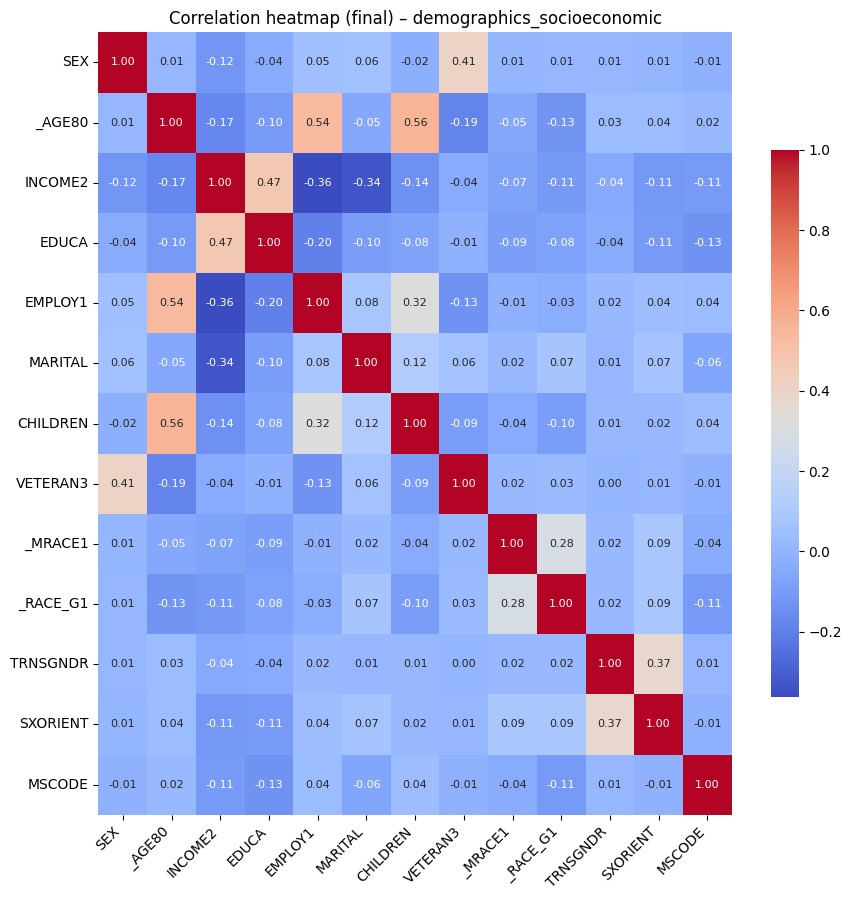

Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\corr_after_final\corr_final_demographics_socioeconomic.png


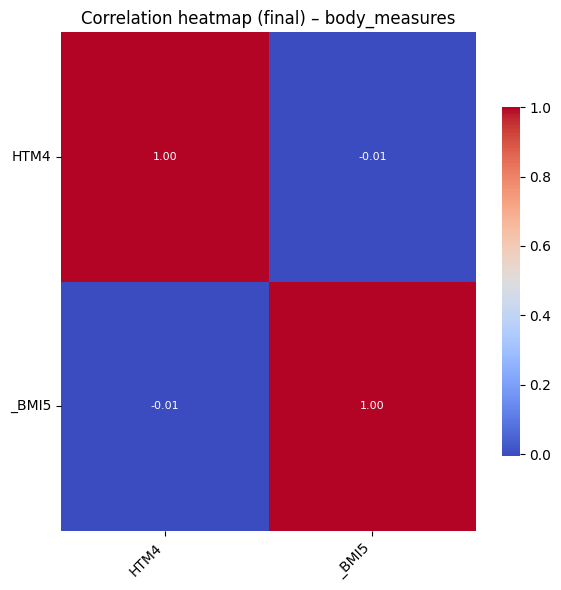

Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\corr_after_final\corr_final_body_measures.png


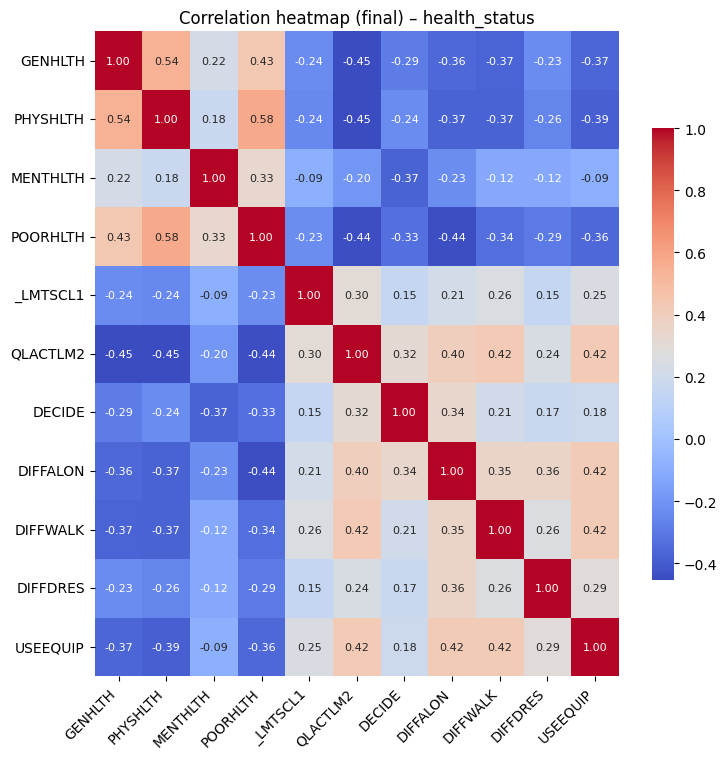

Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\corr_after_final\corr_final_health_status.png


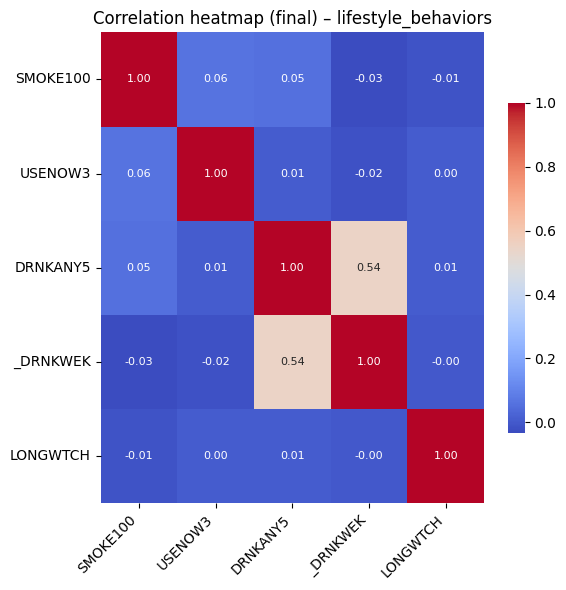

Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\corr_after_final\corr_final_lifestyle_behaviors.png


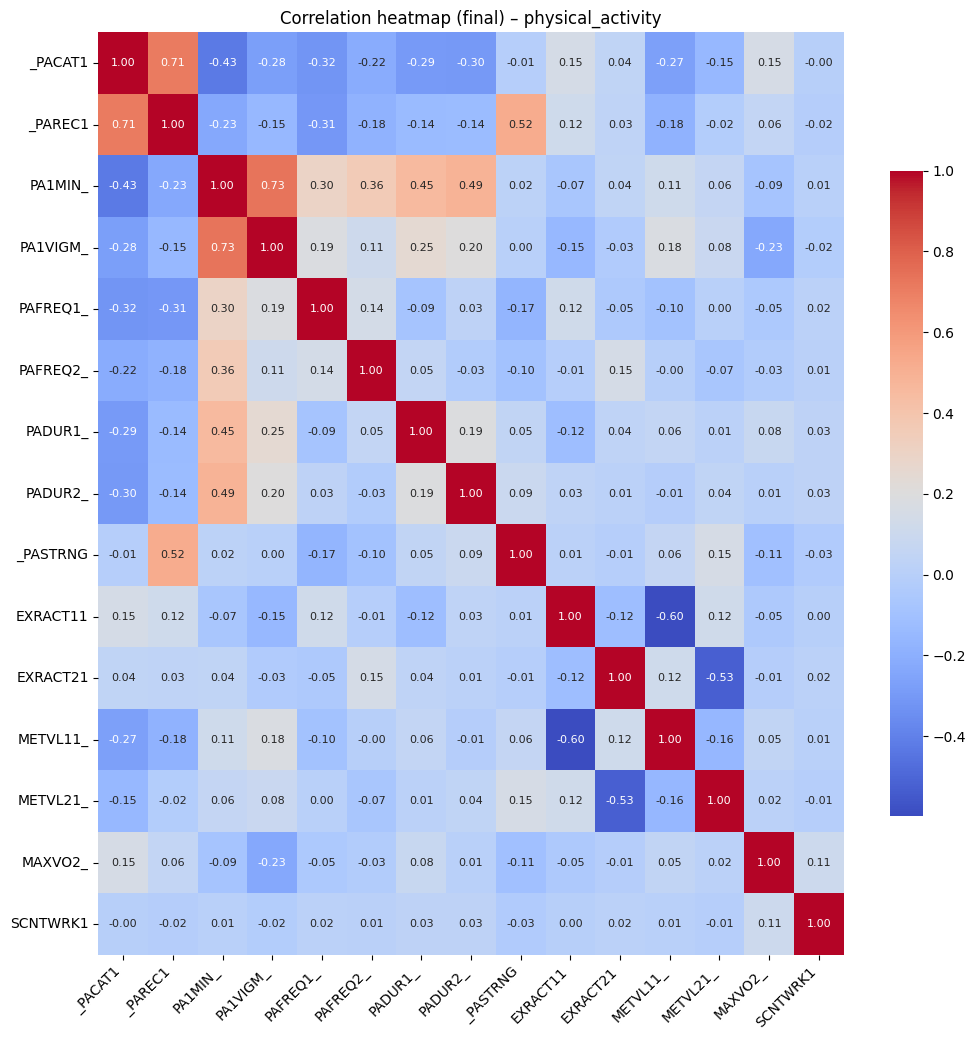

Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\corr_after_final\corr_final_physical_activity.png


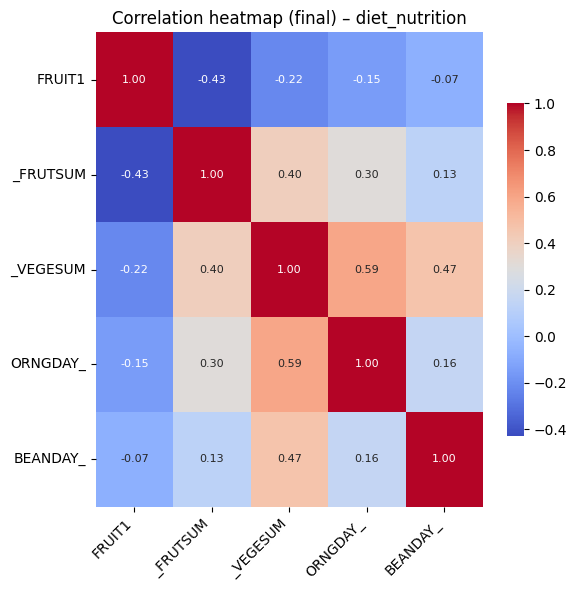

Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\corr_after_final\corr_final_diet_nutrition.png


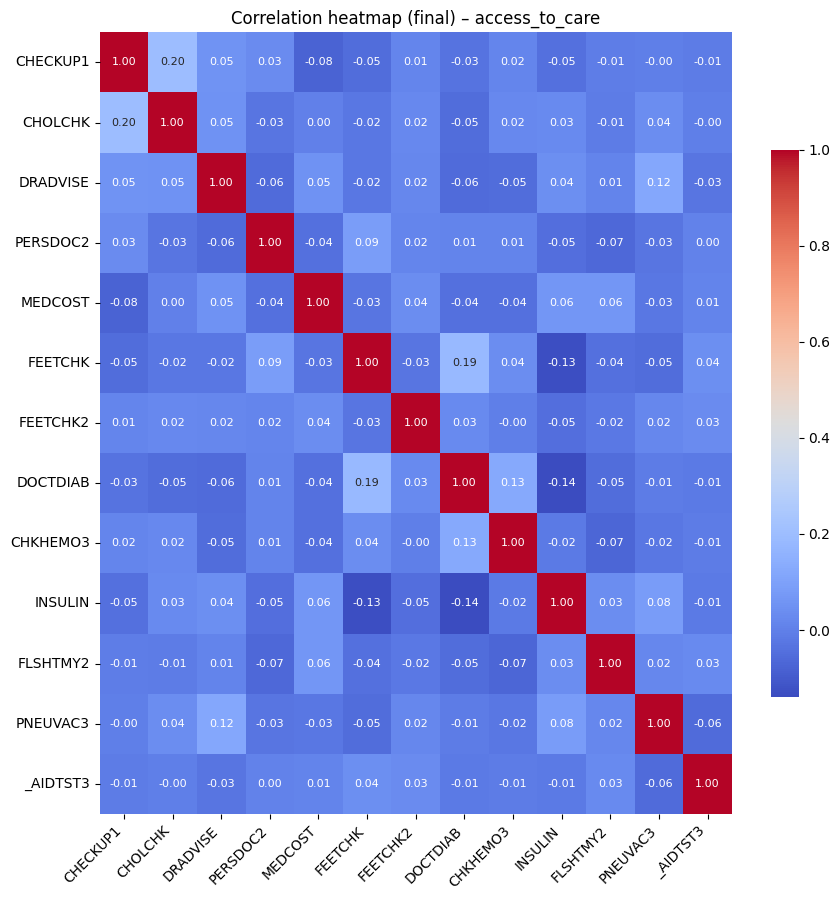

Saved: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\corr_after_final\corr_final_access_to_care.png


In [46]:
# folder for saving (reuse existing structure)
cat_corr_dir = os.path.join(plots_dir, "categories", "corr_after_final")
os.makedirs(cat_corr_dir, exist_ok=True)

# loop over categories
for c, feats in feature_clusters.items():
    # get indices for existing features in this category
    idxs = [x_indices_final[f] for f in feats if f in x_indices_final]
    if len(idxs) < 2:
        continue  # skip single-feature categories

    # subset data
    data_cat = x_train_final[:, idxs]

    # drop rows with any NaN values in this category
    mask = ~np.isnan(data_cat).any(axis=1)
    data_clean = data_cat[mask]

    # skip if too few valid rows
    if data_clean.shape[0] < 5:
        continue

    # drop constant columns (avoid zero std)
    stds = np.nanstd(data_clean, axis=0)
    valid_cols = stds > 0
    data_valid = data_clean[:, valid_cols]
    feats_valid = [f for f, keep in zip(feats, valid_cols) if keep]

    if data_valid.shape[1] < 2:
        print(f"Skipping {c}: not enough non-constant features.")
        continue

    # compute correlation
    corr = np.corrcoef(data_valid, rowvar=False)

    # handle uniform values
    vmin, vmax = np.nanmin(corr), np.nanmax(corr)
    if vmin == vmax:
        vmin, vmax = -1, 1

    # plot size (scale with number of features)
    n = len(feats_valid)
    fig_size = max(6, 0.7 * n)
    plt.figure(figsize=(fig_size, fig_size))

    # heatmap with annotations
    sns.heatmap(
        corr,
        vmin=vmin, vmax=vmax,
        cmap="coolwarm",
        annot=True, fmt=".2f", annot_kws={"size": 8},
        xticklabels=feats_valid, yticklabels=feats_valid,
        cbar_kws={"shrink": 0.7}
    )
    plt.title(f"Correlation heatmap (final) – {c}")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()

    # save + show
    save_path = os.path.join(cat_corr_dir, f"corr_final_{c}.png")
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Saved: {save_path}")

## Feature-target correlations

In [47]:
plots_target_dir = os.path.join(plots_dir, "target_correlations")
os.makedirs(plots_target_dir, exist_ok=True)

plots_summary_dir = os.path.join(plots_dir, "categories", "category_strength")
os.makedirs(plots_summary_dir, exist_ok=True)

print(f"Target correlation plots -> {plots_target_dir}")
print(f"Category summaries -> {plots_summary_dir}")

Target correlation plots -> c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\target_correlations
Category summaries -> c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\category_strength


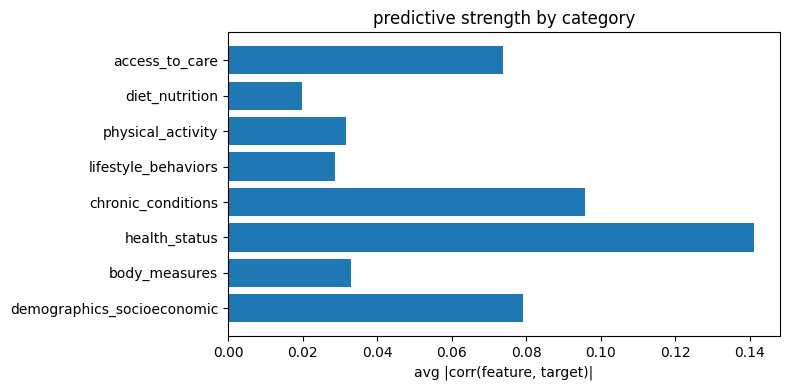

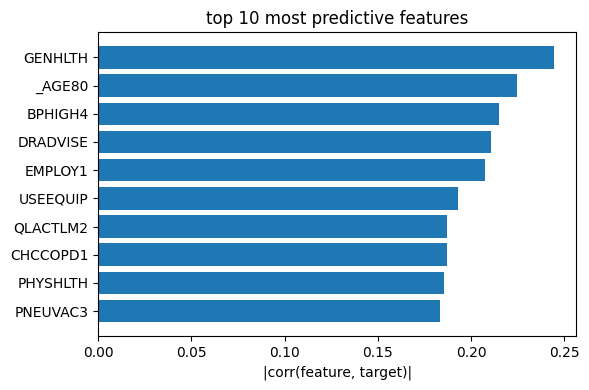

In [48]:
# make sure y is 1d (ignore id column)
y = y_data[:, 1].astype(float)

# sanity checks
assert y.ndim == 1 and len(y) == x_train_final.shape[0], "y has wrong shape"
assert set(np.unique(y)) <= {-1, 1}, "unexpected label values"

# compute feature–target correlations
target_corr = {}
for feat_idx, feat_name in enumerate(reduced_feature_set_final):
    x = x_train_final[:, feat_idx]
    mask = ~np.isnan(x)
    if np.sum(mask) > 5:
        corr = np.corrcoef(x[mask], y[mask])[0, 1]
    else:
        corr = np.nan
    target_corr[feat_name] = corr

# avg abs corr per category
cat_corr_summary = {}
for cat, feats in feature_clusters.items():
    vals = [abs(target_corr[f]) for f in feats if f in target_corr and not np.isnan(target_corr[f])]
    if len(vals) > 0:
        cat_corr_summary[cat] = {
            "mean_abs_corr": np.mean(vals),
            "max_abs_corr": np.max(vals),
            "num_features": len(vals)
        }

# plot avg |corr| per category
cats, avg_corrs = zip(*[(k, v["mean_abs_corr"]) for k, v in cat_corr_summary.items()])
plt.figure(figsize=(8, 4))
plt.barh(cats, avg_corrs)
plt.xlabel("avg |corr(feature, target)|")
plt.title("predictive strength by category")
plt.tight_layout()
plt.savefig(os.path.join(plots_summary_dir, "category_avg_target_corr.png"), dpi=300)
plt.show()

# plot top 10 most predictive features
sorted_feats = sorted(target_corr.items(), key=lambda x: abs(x[1]) if not np.isnan(x[1]) else 0, reverse=True)
top10 = sorted_feats[:10]
plt.figure(figsize=(6, 4))
plt.barh([f[0] for f in top10][::-1], [abs(f[1]) for f in top10][::-1])
plt.xlabel("|corr(feature, target)|")
plt.title("top 10 most predictive features")
plt.tight_layout()
plt.savefig(os.path.join(plots_target_dir, "top10_target_corr.png"), dpi=300)
plt.show()

## Variance structure within-category (PCA / eigenvalue check)

In this step, I examine how much independent variation remains inside each feature category using PCA (via SVD).  
Each category is standardized (mean 0, std 1), and I compute:

- the variance explained by each principal component (shown as a bar plot)  
- the cumulative variance explained (scree plot)  
- how many components are needed to reach 95% of the total variance    

Finally, I print a compact summary of all categories and create an overall bar chart  
showing the variance explained by the **first principal component** across categories.

In [49]:
# make dirs for pca results
plots_pca_dir = os.path.join(plots_categories_dir, "pca")
os.makedirs(plots_pca_dir, exist_ok=True)

results_pca_dir = os.path.join(save_dir, "categories")
os.makedirs(results_pca_dir, exist_ok=True)
pca_csv_path = os.path.join(results_pca_dir, "pca_variance.csv")

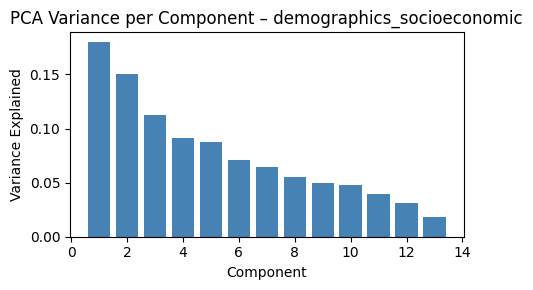

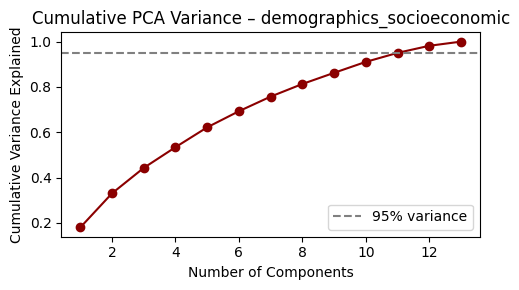

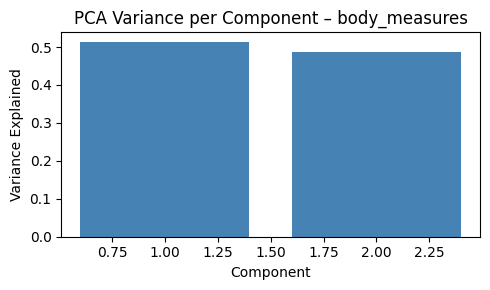

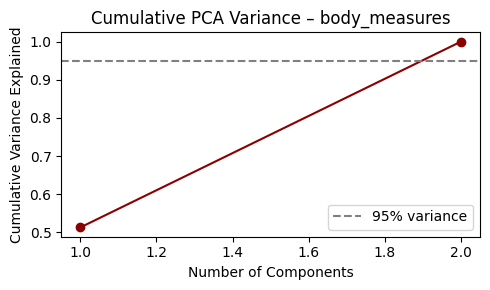

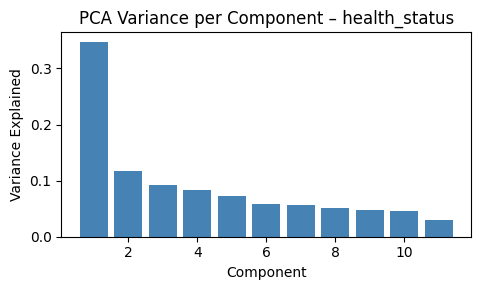

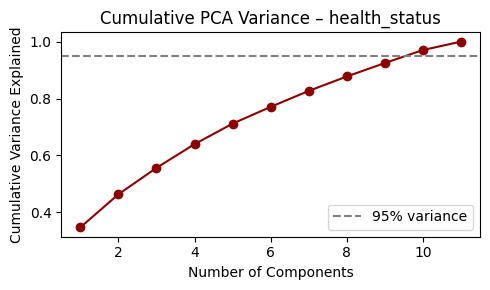

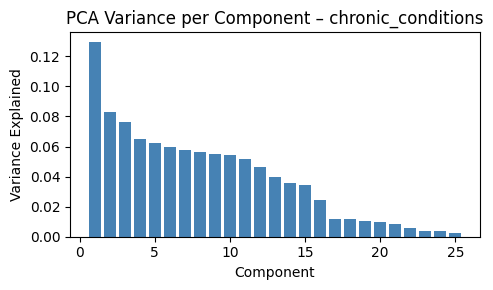

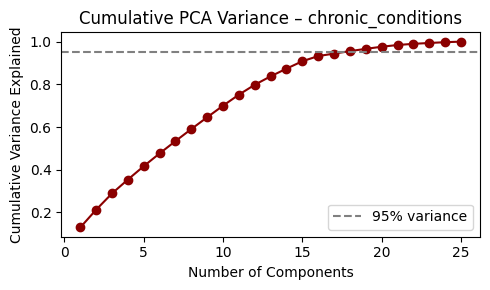

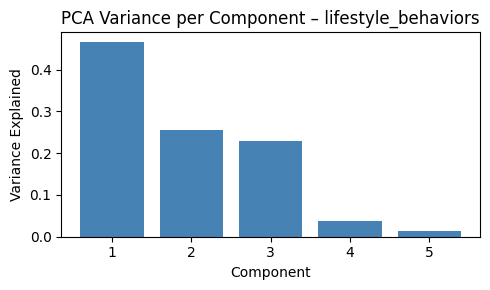

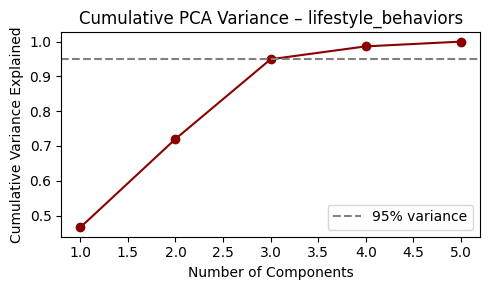

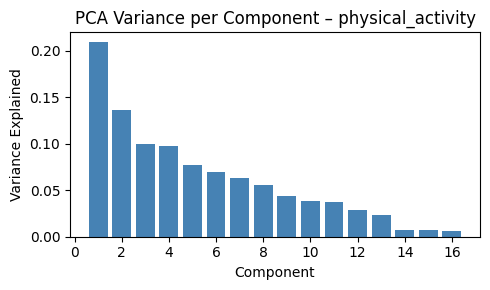

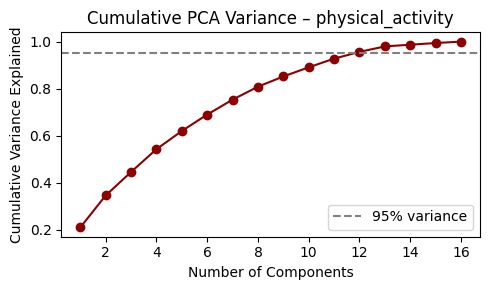

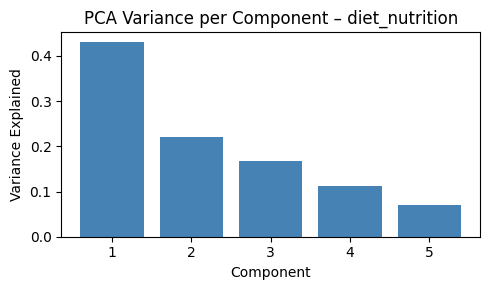

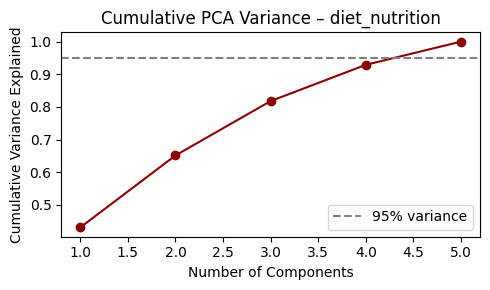

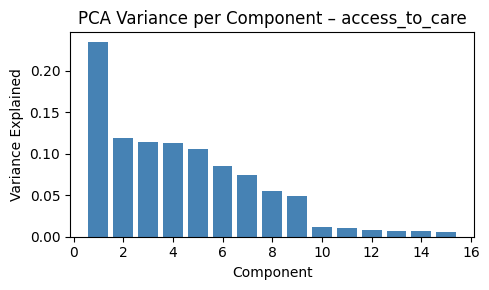

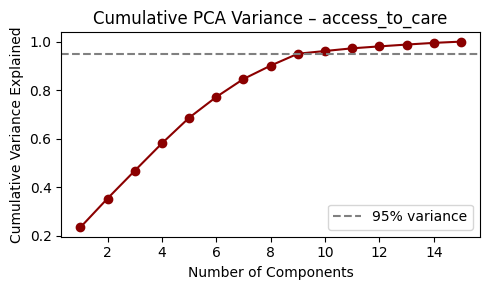


PCA summary by category:

demographics_socioeconomic | features=13 | comps_95=11 | var_first=0.18
body_measures             | features= 2 | comps_95= 2 | var_first=0.51
health_status             | features=11 | comps_95=10 | var_first=0.35
chronic_conditions        | features=25 | comps_95=18 | var_first=0.13
lifestyle_behaviors       | features= 5 | comps_95= 4 | var_first=0.47
physical_activity         | features=16 | comps_95=12 | var_first=0.21
diet_nutrition            | features= 5 | comps_95= 5 | var_first=0.43
access_to_care            | features=15 | comps_95= 9 | var_first=0.23

Saved PCA variance summary: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\results\eda\categories\pca_variance.csv


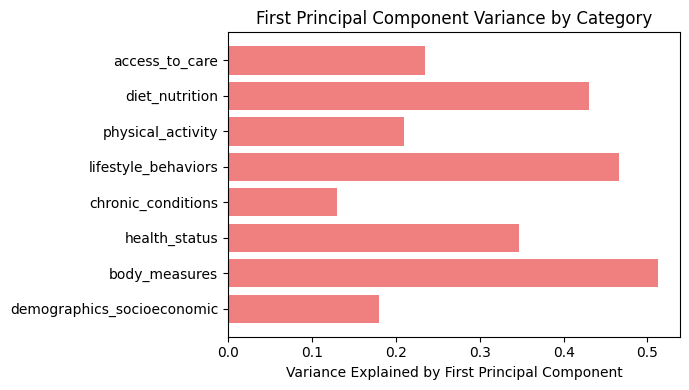

Saved overall PCA summary plot: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\categories\pca\pca_first_component_summary.png


In [50]:
# helper to compute explained variance from svd
def pca_variance(X):
    # standardize
    X_std = (X - np.nanmean(X, axis=0)) / np.nanstd(X, axis=0)
    X_std = np.nan_to_num(X_std, nan=0.0)
    # svd
    U, S, Vt = np.linalg.svd(X_std, full_matrices=False)
    var_ratio = (S**2) / np.sum(S**2)
    cum_ratio = np.cumsum(var_ratio)
    return var_ratio, cum_ratio


# store results
pca_summary = []

for cat, feats in feature_clusters.items():
    # pick valid cols
    idxs = [reduced_feature_set_final.index(f) for f in feats if f in reduced_feature_set_final]
    if len(idxs) == 0:
        continue

    X_cat = x_train_final[:, idxs]
    if np.all(np.isnan(X_cat)):
        print(f"skip {cat}: all NaNs")
        continue

    var_ratio, cum_ratio = pca_variance(X_cat)
    n_comp_95 = np.argmax(cum_ratio >= 0.95) + 1

    # save summary info
    pca_summary.append({
        "category": cat,
        "n_features": len(idxs),
        "n_components_95": n_comp_95,
        "var_first": var_ratio[0],
        "cum_var_95": cum_ratio[n_comp_95 - 1]
    })

    # plot 1: variance explained per component
    plt.figure(figsize=(5, 3))
    plt.bar(np.arange(1, len(var_ratio) + 1), var_ratio, color="steelblue")
    plt.xlabel("Component")
    plt.ylabel("Variance Explained")
    plt.title(f"PCA Variance per Component – {cat}")
    plt.tight_layout()
    save_path_bar = os.path.join(plots_pca_dir, f"pca_var_{cat}.png")
    plt.savefig(save_path_bar, dpi=300)
    plt.show()

    # plot 2: cumulative variance
    plt.figure(figsize=(5, 3))
    plt.plot(np.arange(1, len(cum_ratio) + 1), cum_ratio, marker="o", color="darkred")
    plt.axhline(0.95, color="gray", linestyle="--", label="95% variance")
    plt.xlabel("Number of Components")
    plt.ylabel("Cumulative Variance Explained")
    plt.title(f"Cumulative PCA Variance – {cat}")
    plt.legend()
    plt.tight_layout()
    save_path_cum = os.path.join(plots_pca_dir, f"pca_cum_{cat}.png")
    plt.savefig(save_path_cum, dpi=300)
    plt.show()


# print summary info for all categories
print("\nPCA summary by category:\n")
for row in pca_summary:
    print(f"{row['category']:25s} | features={row['n_features']:2d} | comps_95={row['n_components_95']:2d} | var_first={row['var_first']:.2f}")

# write csv summary
with open(pca_csv_path, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(pca_summary[0].keys()))
    writer.writeheader()
    writer.writerows(pca_summary)

print(f"\nSaved PCA variance summary: {pca_csv_path}")

# plot summary: variance explained by first PC for all categories
cats = [row["category"] for row in pca_summary]
first_var = [row["var_first"] for row in pca_summary]
plt.figure(figsize=(7, 4))
plt.barh(cats, first_var, color="lightcoral")
plt.xlabel("Variance Explained by First Principal Component")
plt.title("First Principal Component Variance by Category")
plt.tight_layout()
save_path_summary = os.path.join(plots_pca_dir, "pca_first_component_summary.png")
plt.savefig(save_path_summary, dpi=300)
plt.show()
print(f"Saved overall PCA summary plot: {save_path_summary}")


### PCA results – takeaways

The PCA results show how much internal redundancy remains inside each category after dropping highly correlated features.

- **demographics_socioeconomic (13 feats, 11 comps for 95%)** → still quite high dimensional. each variable adds its own info (e.g. age, income, education, marital status). low first-component variance (0.18) means no single strong latent factor.  
- **body_measures (2 feats, 2 comps, var_first=0.51)** → expected: height and bmi only moderately related, both needed to capture variance.  
- **health_status (11 feats, 10 comps, var_first=0.35)** → also fairly independent indicators (physical and mental health, limitations, etc.).  
- **chronic_conditions (25 feats, 18 comps, var_first=0.13)** → very high dimensional; diseases behave mostly independently, so compression would lose info.  
- **lifestyle_behaviors (5 feats, 4 comps, var_first=0.47)** → some overlap (e.g. smoking/drinking), but overall still diverse.  
- **physical_activity (16 feats, 12 comps, var_first=0.21)** → moderate redundancy, makes sense since many variables describe related activity levels.  
- **diet_nutrition (5 feats, 5 comps, var_first=0.43)** → relatively independent diet metrics.  
- **access_to_care (15 feats, 9 comps, var_first=0.23)** → moderate overlap between health check and vaccination features.

In short, most categories remain quite rich and not strongly compressible - suggesting that the reduced feature set still captures multiple independent aspects of health behavior and status.


## Cross-category correlations

In [51]:
# make dirs for plots and results
plots_corr_dir = os.path.join(plots_categories_dir, "corr")
os.makedirs(plots_corr_dir, exist_ok=True)

results_corr_dir = os.path.join(save_dir, "categories", "corr")
os.makedirs(results_corr_dir, exist_ok=True)

C:\Users\emmaa\AppData\Local\Temp\ipykernel_21356\2196759682.py:8: RuntimeWarning: Mean of empty slice
  cat_means[cat] = np.nanmean(X_cat, axis=1)


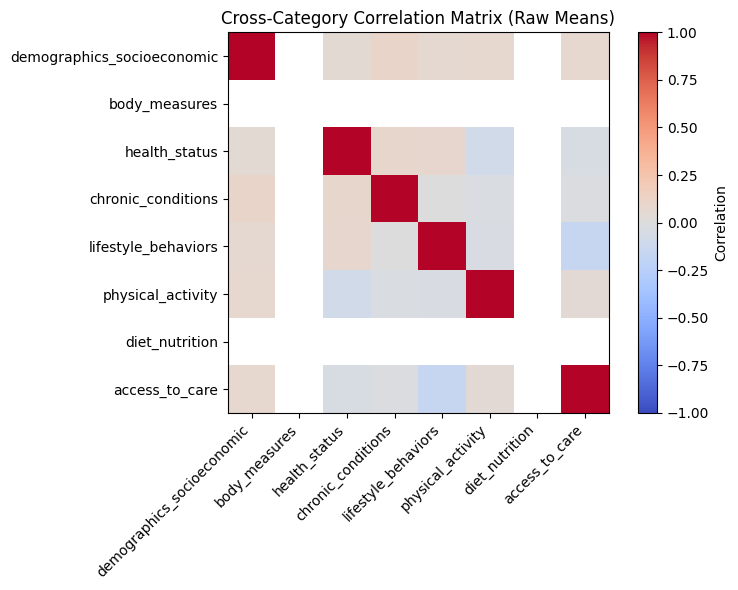

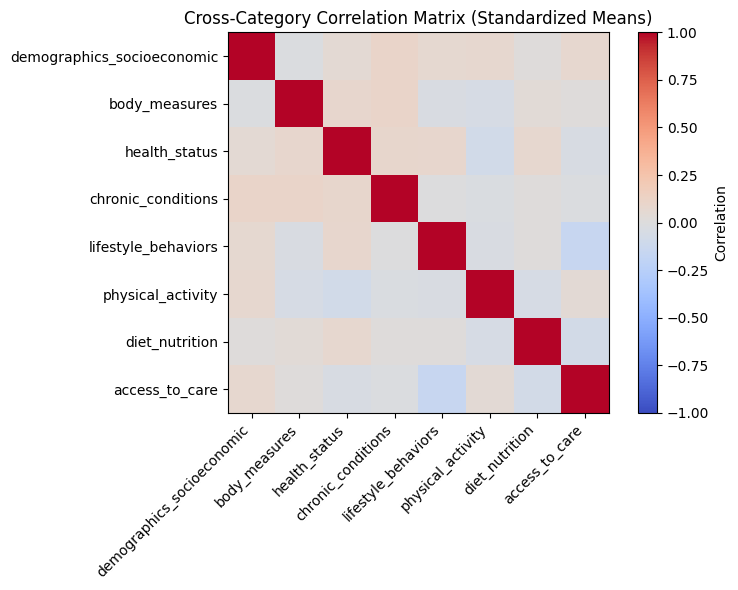


=== Cross-category correlations (standardized means) ===

lifestyle_behaviors       <--> access_to_care             r=-0.155
demographics_socioeconomic <--> chronic_conditions         r=+0.104
body_measures             <--> chronic_conditions         r=+0.102
health_status             <--> chronic_conditions         r=+0.094
health_status             <--> physical_activity          r=-0.085
health_status             <--> lifestyle_behaviors        r=+0.083
body_measures             <--> health_status              r=+0.080
demographics_socioeconomic <--> physical_activity          r=+0.078
demographics_socioeconomic <--> access_to_care             r=+0.078
health_status             <--> diet_nutrition             r=+0.075
diet_nutrition            <--> access_to_care             r=-0.072
demographics_socioeconomic <--> lifestyle_behaviors        r=+0.067
physical_activity         <--> diet_nutrition             r=-0.053
body_measures             <--> physical_activity          r=-0.051

In [52]:
# compute mean value per category for each sample
cat_means = {}
for cat, feats in feature_clusters.items():
    idxs = [reduced_feature_set_final.index(f) for f in feats if f in reduced_feature_set_final]
    if len(idxs) == 0:
        continue
    X_cat = x_train_final[:, idxs]
    cat_means[cat] = np.nanmean(X_cat, axis=1)

# build matrix of category means
cat_names = list(cat_means.keys())
cat_matrix = np.vstack([cat_means[c] for c in cat_names]).T

# compute correlation matrix (raw)
corr_mat = np.corrcoef(cat_matrix, rowvar=False)
np.save(os.path.join(results_corr_dir, "inter_category_corr_raw.npy"), corr_mat)

# plot raw correlation heatmap
plt.figure(figsize=(8, 6))
plt.imshow(corr_mat, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(cat_names)), cat_names, rotation=45, ha="right")
plt.yticks(range(len(cat_names)), cat_names)
plt.title("Cross-Category Correlation Matrix (Raw Means)")
plt.tight_layout()
save_path_raw = os.path.join(plots_corr_dir, "inter_category_corr_raw.png")
plt.savefig(save_path_raw, dpi=300)
plt.show()

# standardize category means before correlation (fix for NaNs)
cat_matrix_std = (cat_matrix - np.nanmean(cat_matrix, axis=0)) / np.nanstd(cat_matrix, axis=0)
cat_matrix_std = np.nan_to_num(cat_matrix_std, nan=0.0)

# recompute correlation matrix on standardized data
corr_mat_std = np.corrcoef(cat_matrix_std, rowvar=False)
np.save(os.path.join(results_corr_dir, "inter_category_corr_standardized.npy"), corr_mat_std)

# plot standardized correlation heatmap
plt.figure(figsize=(8, 6))
plt.imshow(corr_mat_std, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(cat_names)), cat_names, rotation=45, ha="right")
plt.yticks(range(len(cat_names)), cat_names)
plt.title("Cross-Category Correlation Matrix (Standardized Means)")
plt.tight_layout()
save_path_std = os.path.join(plots_corr_dir, "inter_category_corr_standardized.png")
plt.savefig(save_path_std, dpi=300)
plt.show()

# print sorted pairwise correlations (standardized)
pairs = []
n = len(cat_names)
for i in range(n):
    for j in range(i + 1, n):
        r = corr_mat_std[i, j]
        if not np.isnan(r):
            pairs.append((cat_names[i], cat_names[j], r))

# sort by absolute correlation, descending
pairs_sorted = sorted(pairs, key=lambda x: abs(x[2]), reverse=True)

print("\n=== Cross-category correlations (standardized means) ===\n")
for a, b, r in pairs_sorted:
    print(f"{a:25s} <--> {b:25s}  r={r:+.3f}")

# save printed correlations to file
corr_txt_path = os.path.join(results_corr_dir, "inter_category_corr_pairs.txt")
with open(corr_txt_path, "w") as f:
    for a, b, r in pairs_sorted:
        f.write(f"{a:25s} <--> {b:25s}  r={r:+.3f}\n")

After standardizing category-level means, correlations between feature categories are generally weak (|r| < 0.2), which suggests that the main health domains are largely independent - a good sign, since it means the categories capture distinct aspects of the data rather than overlapping information.

A few small trends appear:

- **Lifestyle behaviors ↔ Access to care (r = –0.16)**: Individuals with riskier behaviors may engage less with healthcare systems or preventive services.
- **Demographics & socioeconomic ↔ Chronic conditions (r = +0.10)**: Slight positive link, consistent with age and income effects on chronic disease prevalence.
- **Body measures ↔ Chronic conditions (r = +0.10)** and **Health status ↔ Chronic conditions (r = +0.09)**: Expected mild associations, since BMI and self-reported health often relate to chronic illness.
- **Health status ↔ Physical activity (r = –0.09)**: Individuals reporting worse health may be less active.

Overall, no strong inter-category dependencies remain - confirming that the **final reduced feature set is well-balanced and non-redundant** across domains.

# 5. Feature normalization, Imputation

## Scaling

In [53]:
plots_scaling_dir = os.path.join(plots_dir, "eda", "scaling")
os.makedirs(plots_scaling_dir, exist_ok=True)
results_scaling_dir = os.path.join(save_dir, "eda", "scaling")
os.makedirs(results_scaling_dir, exist_ok=True)

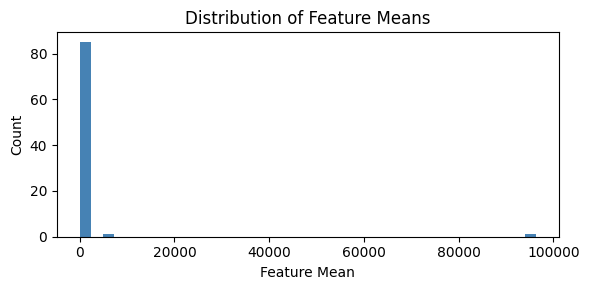

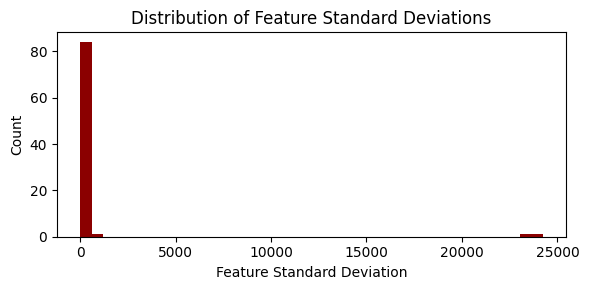

High-variance features (>3× median std): 25
MENTHLTH, DOCTDIAB, DIABAGE2, CHKHEMO3, _DRNKWEK, FRUIT1, PADUR2_, PAFREQ2_, POORHLTH, EXRACT21, FEETCHK, EXRACT11, _BMI5, _MRACE1, PHYSHLTH, PADUR1_, FLSHTMY2, PA1VIGM_, PA1MIN_, MAXVO2_, LONGWTCH, SCNTWRK1, FEETCHK2, _AGE80, CHILDREN


In [54]:
# compute per-feature mean and std (ignoring NaNs)
means = np.nanmean(x_train_final, axis=0)
stds = np.nanstd(x_train_final, axis=0)

# detect high-variance features
high_var_idx = np.where(stds > np.nanmedian(stds) * 3)[0]
high_var_feats = [reduced_feature_set_final[i] for i in high_var_idx]

# plot histograms
plt.figure(figsize=(6, 3))
plt.hist(means, bins=40, color="steelblue")
plt.xlabel("Feature Mean")
plt.ylabel("Count")
plt.title("Distribution of Feature Means")
plt.tight_layout()
plt.savefig(os.path.join(plots_scaling_dir, "feature_means.png"), dpi=300)
plt.show()

plt.figure(figsize=(6, 3))
plt.hist(stds, bins=40, color="darkred")
plt.xlabel("Feature Standard Deviation")
plt.ylabel("Count")
plt.title("Distribution of Feature Standard Deviations")
plt.tight_layout()
plt.savefig(os.path.join(plots_scaling_dir, "feature_stds.png"), dpi=300)
plt.show()

print(f"High-variance features (>3× median std): {len(high_var_feats)}")
if len(high_var_feats) > 0:
    print(", ".join(high_var_feats[:]))

In [55]:
# === normalize the data (z-score) and save ===
x_train_norm = (x_train_final - means) / stds
x_train_norm = np.nan_to_num(x_train_norm, nan=0.0)
np.save(os.path.join(results_scaling_dir, "x_train_normalized.npy"), x_train_norm)
print("Saved normalized version: x_train_normalized.npy")

Saved normalized version: x_train_normalized.npy


## Imputation

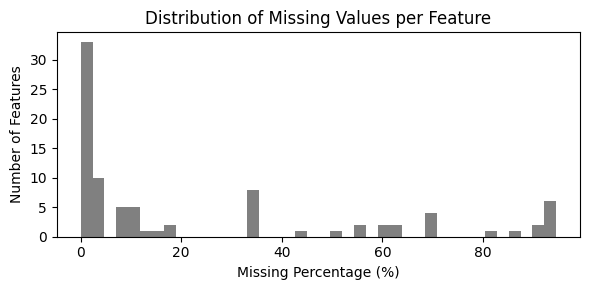

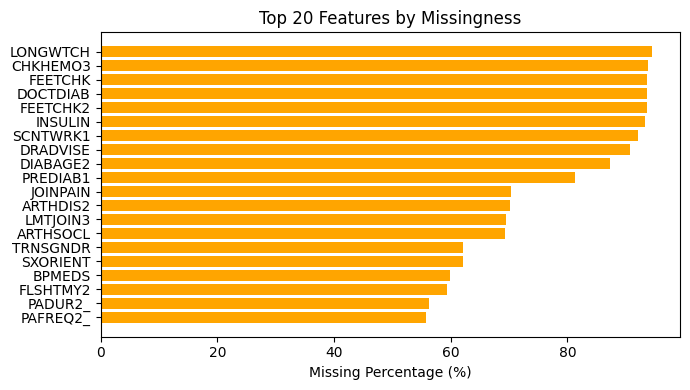

Saved missing ratio summary: c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\results\eda\eda\missingness\missing_ratio_per_feature.txt

=== Suggested Imputation Strategy ===
demographics_socioeconomic -> median               (avg missing  14.4%)
body_measures             -> median               (avg missing   5.9%)
health_status             -> median               (avg missing   6.5%)
chronic_conditions        -> mode / categorical fill (avg missing  36.1%)
lifestyle_behaviors       -> median               (avg missing  20.5%)
physical_activity         -> mode / categorical fill (avg missing  30.9%)
diet_nutrition            -> median               (avg missing   9.5%)
access_to_care            -> mode / categorical fill (avg missing  44.9%)


In [56]:
# === STEP 5 — missingness diagnostics and imputation overview ===
plots_missing_dir = os.path.join(plots_dir, "eda", "missingness")
os.makedirs(plots_missing_dir, exist_ok=True)
results_missing_dir = os.path.join(save_dir, "eda", "missingness")
os.makedirs(results_missing_dir, exist_ok=True)

# compute per-feature missing ratio
missing_ratio = np.isnan(x_train_final).mean(axis=0)
sorted_idx = np.argsort(missing_ratio)[::-1]
sorted_missing = missing_ratio[sorted_idx]
sorted_feats = [reduced_feature_set_final[i] for i in sorted_idx]

# plot histogram of missing percentages
plt.figure(figsize=(6, 3))
plt.hist(missing_ratio * 100, bins=40, color="gray")
plt.xlabel("Missing Percentage (%)")
plt.ylabel("Number of Features")
plt.title("Distribution of Missing Values per Feature")
plt.tight_layout()
plt.savefig(os.path.join(plots_missing_dir, "missing_ratio_hist.png"), dpi=300)
plt.show()

# visualize top missing features as barplot
top_k = 20
plt.figure(figsize=(7, 4))
plt.barh(sorted_feats[:top_k][::-1], sorted_missing[:top_k][::-1] * 100, color="orange")
plt.xlabel("Missing Percentage (%)")
plt.title(f"Top {top_k} Features by Missingness")
plt.tight_layout()
plt.savefig(os.path.join(plots_missing_dir, "top_missing_features.png"), dpi=300)
plt.show()

# save summary
missing_summary_path = os.path.join(results_missing_dir, "missing_ratio_per_feature.txt")
with open(missing_summary_path, "w") as f:
    for feat, ratio in zip(sorted_feats, sorted_missing):
        f.write(f"{feat:25s} {ratio*100:6.2f}%\n")
print(f"Saved missing ratio summary: {missing_summary_path}")

# recommend basic imputation rule per category
print("\n=== Suggested Imputation Strategy ===")
for cat, feats in feature_clusters.items():
    idxs = [reduced_feature_set_final.index(f) for f in feats if f in reduced_feature_set_final]
    if len(idxs) == 0:
        continue
    miss_cat = np.isnan(x_train_final[:, idxs]).mean(axis=0)
    avg_miss = np.nanmean(miss_cat)
    if avg_miss < 0.05:
        rule = "mean"
    elif avg_miss < 0.25:
        rule = "median"
    else:
        rule = "mode / categorical fill"
    print(f"{cat:25s} -> {rule:20s} (avg missing {avg_miss*100:5.1f}%)")

In [58]:
print(reduced_feature_set_final)

['_CASTHM1', 'FLUSHOT6', 'METVL11_', '_PASTRNG', 'EDUCA', 'CHCCOPD1', 'DRADVISE', 'CHCKIDNY', 'ARTHSOCL', 'MENTHLTH', 'SMOKE100', 'DOCTDIAB', 'DIABAGE2', 'VETERAN3', 'CHKHEMO3', 'SEX', '_DRNKWEK', 'JOINPAIN', 'MARITAL', 'EXERANY2', '_PACAT1', 'INSULIN', 'DIFFALON', 'FRUIT1', 'QLACTLM2', 'BLIND', 'PADUR2_', 'PAFREQ2_', 'LMTJOIN3', 'CHOLCHK', 'POORHLTH', 'DIABETE3', '_FRUTSUM', 'PERSDOC2', 'EXRACT21', 'FEETCHK', '_VEGESUM', 'PNEUVAC3', 'BPHIGH4', 'GENHLTH', 'EXRACT11', '_BMI5', 'DECIDE', '_ASTHMS1', '_MRACE1', '_LMTSCL1', 'ORNGDAY_', 'MSCODE', 'PHYSHLTH', 'TOLDHI2', 'PADUR1_', 'DIFFWALK', 'BEANDAY_', 'CHCSCNCR', 'PAFREQ1_', '_AIDTST3', 'FLSHTMY2', 'PA1VIGM_', 'METVL21_', 'SXORIENT', 'ARTHDIS2', 'PA1MIN_', 'MAXVO2_', '_RACE_G1', 'LONGWTCH', 'SCNTWRK1', 'FEETCHK2', 'EMPLOY1', 'BLOODCHO', 'USENOW3', 'DRNKANY5', '_PAREC1', 'DIFFDRES', 'USEEQUIP', 'ADDEPEV2', '_AGE80', 'HTM4', 'INCOME2', 'CVDSTRK3', 'CHCOCNCR', 'MEDCOST', 'PREDIAB1', 'BPMEDS', 'HAVARTH3', 'CHECKUP1', 'TRNSGNDR', 'CHILDREN']
